# Non-pregnant anemia prevalence and DALYs averted by fortification

We take a "multiplication model" approach here, shifting continuous hemoglobin (as estimated
by GBD) and seeing what impact that has on anemia and therefore YLDs.

It's important to note that we directly use hemoglobin estimates, which are the first step
of the GBD anemia estimation pipeline. The risks and causes that are related to anemia are
all calculated downstream from this.

In [1]:
import vivarium.gbd_mapping as gbd_mapping
import pathlib
import pandas as pd, numpy as np
import vivarium_inputs
from vivarium_gbd_access.shared_functions import get_ids
import warnings
from lsff_utils import config_utils, paths
from lsff_utils import gbd_data
from lsff_utils.hemoglobin_distribution import (
    hemoglobin_pdf_from_mean_sd,
    hemoglobin_cdf_from_mean_sd,
)

from vivarium_inputs.validation.raw import DataDoesNotExistError, DataAbnormalError
from tqdm.notebook import tqdm

In [2]:
pd.set_option("display.max_columns", 30)

In [3]:
warnings.simplefilter(action="ignore", category=pd.errors.PerformanceWarning)

In [4]:
location = "india"
vehicle = "rice"

In [5]:
# Parameters
location = "nigeria"
vehicle = "wheat"


In [6]:
intervention_scenarios = config_utils.get_intervention_scenarios(location, vehicle)
intervention_scenarios

['intervention']

## Setup and scenarios

In [7]:
# GBD estimation year every pull below uses. Owned by gbd_data; shown here
# so a run's output records which year it was built against.
gbd_data.most_recent_year()

2023

In [8]:
# Save the set of draws used in gbd_data when pulling modelable entities
# so we can make sure to use the same draws for the sequela prevalences
# below
DRAWS = gbd_data.DRAWS
len(DRAWS)

250

In [9]:
effective_coverage_baseline = pd.read_csv(
    f"../0100_data_prep/results/iron/{vehicle}/baseline_fortification/effective_coverage/{location}.csv"
)
assert (effective_coverage_baseline.vehicle_name == vehicle).all()
effective_coverage_baseline = effective_coverage_baseline.drop(columns=["vehicle_name"])
effective_coverage_baseline

,wealth_quintile,value
0,1,0.119203
1,2,0.157897
2,3,0.190351
3,4,0.207825
4,5,0.220307


In [10]:
def expand(df):
    for col in sorted(list(set(df.columns) - {"value"})):
        if df[col].isnull().any():
            df = pd.concat(
                [
                    df[df[col].notnull()],
                    *[
                        df[df[col].isnull()].assign(**{col: value})
                        for value in df[df[col].notnull()][col].unique()
                    ],
                ]
            )

    return df

In [11]:
for col, fill_value in [("age_start", 0), ("age_end", 125)]:
    if col not in effective_coverage_baseline.columns:
        effective_coverage_baseline[col] = fill_value
    else:
        effective_coverage_baseline[col] = effective_coverage_baseline[col].fillna(
            fill_value
        )

In [12]:
effective_coverage_baseline = expand(effective_coverage_baseline)
effective_coverage_baseline

,wealth_quintile,value,age_start,age_end
0,1,0.119203,0,125
1,2,0.157897,0,125
2,3,0.190351,0,125
3,4,0.207825,0,125
4,5,0.220307,0,125


In [13]:
effective_coverage_intervention = pd.concat(
    [
        pd.read_csv(
            f"../0100_data_prep/results/iron/{vehicle}/{intervention_scenario}/intervention_fortification/effective_coverage/{location}.csv"
        ).assign(scenario=intervention_scenario)
        for intervention_scenario in intervention_scenarios
    ]
)
assert (effective_coverage_intervention.vehicle_name == vehicle).all()
effective_coverage_intervention = effective_coverage_intervention.drop(
    columns=["vehicle_name"]
)
effective_coverage_intervention

,wealth_quintile,sex,value,scenario
0,1,Female,0.161662,intervention
1,1,Male,0.161662,intervention
2,2,Female,0.214139,intervention
3,2,Male,0.214139,intervention
4,3,Female,0.258152,intervention
5,3,Male,0.258152,intervention
6,4,Female,0.281851,intervention
7,4,Male,0.281851,intervention
8,5,Female,0.298779,intervention
9,5,Male,0.298779,intervention


In [14]:
for col, fill_value in [("age_start", 0), ("age_end", 125)]:
    if col not in effective_coverage_intervention.columns:
        effective_coverage_intervention[col] = fill_value
    else:
        effective_coverage_intervention[col] = effective_coverage_intervention[
            col
        ].fillna(fill_value)

In [15]:
effective_coverage_intervention = expand(effective_coverage_intervention)
effective_coverage_intervention

,wealth_quintile,sex,value,scenario,age_start,age_end
0,1,Female,0.161662,intervention,0,125
1,1,Male,0.161662,intervention,0,125
2,2,Female,0.214139,intervention,0,125
3,2,Male,0.214139,intervention,0,125
4,3,Female,0.258152,intervention,0,125
5,3,Male,0.258152,intervention,0,125
6,4,Female,0.281851,intervention,0,125
7,4,Male,0.281851,intervention,0,125
8,5,Female,0.298779,intervention,0,125
9,5,Male,0.298779,intervention,0,125


In [16]:
population = pd.read_csv(
    f"../0100_data_prep/results/population/stratified/{location}.csv"
)

In [17]:
non_pregnant_pop = population.pipe(lambda df: df[df.pregnant == "not_pregnant"]).drop(
    columns="pregnant"
)
non_pregnant_pop = non_pregnant_pop.set_index(
    [c for c in non_pregnant_pop.columns if c != "value"]
).value
non_pregnant_pop

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  18793.149621
                               2                  17830.620200
                               3                  16129.662368
                               4                  14114.028154
                               5                  12208.445301
                                                      ...     
Male    95.0       125.000000  1                   4849.649774
                               2                   4371.181536
                               3                   4569.918352
                               4                   4550.906874
                               5                   5750.658068
Name: value, Length: 250, dtype: float64

In [18]:
example_sex = "Female"
example_age_start = 25
example_age_end = 30
example_wealth_quintile = 1
example_tuple = (
    example_sex,
    example_age_start,
    example_age_end,
    example_wealth_quintile,
)

In [19]:
population.set_index(["sex", "age_start", "age_end"]).loc[
    (example_sex, example_age_start, example_age_end)
].value.sum()

np.float64(9984802.005639391)

In [20]:
non_pregnant_pop.loc[(example_sex, example_age_start, example_age_end)][1]

np.float64(1252305.7828305052)

In [21]:
non_pregnant_pop.loc[(example_sex, example_age_start, example_age_end)].sum()

np.float64(7562913.436395377)

In [22]:
population_age_groups = (
    non_pregnant_pop.reset_index()[["age_start", "age_end"]]
    .drop_duplicates()
    .sort_values("age_start")
)
population_age_groups

,age_start,age_end
0,0.000000,0.019178
5,0.019178,0.076712
10,0.076712,0.500000
15,0.500000,1.000000
20,1.000000,2.000000
25,2.000000,5.000000
30,5.000000,10.000000
35,10.000000,15.000000
40,15.000000,20.000000
45,20.000000,25.000000


In [23]:
def map_to_population_age_groups(df):
    result = (
        population_age_groups.merge(df, how="cross", suffixes=("", "_orig"))
        .pipe(
            lambda df: df[
                (df.age_end <= df.age_end_orig) & (df.age_start >= df.age_start_orig)
            ]
        )
        .drop(columns=["age_start_orig", "age_end_orig"])
    )
    return result

In [24]:
effective_coverage_baseline = (
    map_to_population_age_groups(effective_coverage_baseline)
    .set_index([c for c in effective_coverage_baseline.columns if c != "value"])
    .value
)
effective_coverage_intervention = (
    map_to_population_age_groups(effective_coverage_intervention)
    .set_index([c for c in effective_coverage_intervention.columns if c != "value"])
    .value
)

In [25]:
if "sex" not in effective_coverage_baseline.index.names:
    # Assume does not vary
    effective_coverage_baseline = pd.concat(
        [
            effective_coverage_baseline.reset_index()
            .assign(sex="Female")
            .set_index(["wealth_quintile", "sex", "age_start", "age_end"])
            .value,
            effective_coverage_baseline.reset_index()
            .assign(sex="Male")
            .set_index(["wealth_quintile", "sex", "age_start", "age_end"])
            .value,
        ]
    )

In [26]:
effective_coverage_baseline = (
    effective_coverage_baseline.reset_index()
    .set_index(["sex", "age_start", "age_end", "wealth_quintile"])
    .value
)

In [27]:
if "sex" not in effective_coverage_intervention.index.names:
    # Assume does not vary
    effective_coverage_intervention = pd.concat(
        [
            effective_coverage_intervention.to_frame()
            .assign(sex="Female")
            .set_index("sex", append=True)
            .reorder_levels(["sex", "age_start", "age_end", "wealth_quintile"])
            .value,
            effective_coverage_intervention.to_frame()
            .assign(sex="Male")
            .set_index("sex", append=True)
            .reorder_levels(["sex", "age_start", "age_end", "wealth_quintile"])
            .value,
        ]
    )

In [28]:
effective_coverage_intervention = effective_coverage_intervention.reorder_levels(
    ["sex", "age_start", "age_end", "wealth_quintile", "scenario"]
)

In [29]:
effective_coverage_baseline.loc[example_tuple]

np.float64(0.1192031)

In [30]:
effective_coverage_intervention.loc[example_tuple]

scenario
intervention    0.161662
Name: value, dtype: float64

## Pull GBD hemoglobin distribution statistics

In [31]:
me_ids = {
    "hemoglobin_mean": 10487,
    "hemoglobin_sd": 10488,
}
me_release_id = 33

# Verify the MEIDs against get_ids
meids_df = get_ids('modelable_entity')
assert (
    meids_df.loc[
        meids_df['modelable_entity_id'] == me_ids["hemoglobin_mean"],
        'modelable_entity_name'].squeeze()
        == 'Mean Hemoglobin (g/L, elevation adjusted) - Custom')
assert (
    meids_df.loc[
        meids_df['modelable_entity_id'] == me_ids["hemoglobin_sd"],
        'modelable_entity_name'].squeeze()
        == 'Standard Deviation of Hemoglobin (g/L, survey elevation adjusted)')


2026-11-11 00:25:06.153 | INFO     | vivarium_gbd_access._remote.dispatch:dispatch:147 - Shared functions call: get_ids('modelable_entity')


2026-11-11 00:25:09.785 | DEBUG    | vivarium_gbd_access._remote.dispatch:dispatch:186 - GBD worker ran pandas 1.5.3; this environment has 3.1.1.


In [32]:
gbd_hgb_mean = gbd_data.pull_modelable_entity_draws(
    me_ids["hemoglobin_mean"], location, release_id=me_release_id
)
gbd_hgb_mean

draw_0      draw_1      draw_2      draw_3  \
sex    age_start age_end                                                      
Female 0.000000  0.019178    144.483481  134.387541  138.797388  141.751704   
       0.019178  0.076712    128.073491  119.124217  123.033207  125.651981   
       0.076712  0.500000    104.357617   97.065515  100.250663  102.384508   
       0.500000  1.000000    102.788400   97.664230   98.012729   99.808849   
       1.000000  2.000000    102.549998   97.184079   97.277015   98.987528   
       2.000000  5.000000    107.538317  102.129244  102.054849  104.085893   
       5.000000  10.000000   117.743379  109.515933  113.109633  115.517182   
       10.000000 15.000000   121.116002  112.814400  116.362439  118.822984   
       15.000000 20.000000   119.955567  113.495732  114.134254  116.151145   
       20.000000 25.000000   120.336219  113.843668  114.587471  116.656684   
       25.000000 30.000000   121.505460  114.972416  115.675382  117.725377   
       30.000000 35.000000   120.145120  114.008910  114.674545  116.777891   
       35.000000 40.000000   120.348489  113.886415  114.605779  116.651617   
       40.000000 45.000000   120.224723  113.715717  114.497560  116.574135   
       45.000000 50.000000   121.602427  115.436068  116.177091  118.410395   
       50.000000 55.000000   123.489117  114.860181  118.629249  121.154285   
       55.000000 60.000000   124.402731  115.709955  119.506909  122.050625   
       60.000000 65.000000   125.140542  116.396211  120.215684  122.774486   
       65.000000 70.000000   125.505181  116.735370  120.565972  123.132231   
       70.000000 75.000000   126.334058  117.506328  121.362229  123.945436   
       75.000000 80.000000   125.187486  116.439875  120.260780  122.820543   
       80.000000 85.000000   125.250159  116.498168  120.320986  122.882030   
       85.000000 90.000000   125.060309  116.321585  120.138608  122.695770   
       90.000000 95.000000   122.366061  113.815600  117.550391  120.052463   
       95.000000 125.000000  120.360633  111.950304  115.623886  118.084952   
Male   0.000000  0.019178    149.937654  139.791506  144.226245  147.194650   
       0.019178  0.076712    127.284845  118.671592  122.436325  124.956259   
       0.076712  0.500000    102.765983   95.811900   98.851433  100.885952   
       0.500000  1.000000    100.716801   96.167586   96.624299   98.365756   
       1.000000  2.000000    100.256022   95.544554   95.752270   97.440477   
       2.000000  5.000000    106.325675  100.646451  100.635415  102.289042   
       5.000000  10.000000   118.032689  110.045522  113.536601  115.873365   
       10.000000 15.000000   125.425649  116.938207  120.647949  123.131076   
       15.000000 20.000000   138.354449  128.992126  133.084267  135.823353   
       20.000000 25.000000   142.706771  133.049931  137.270801  140.096052   
       25.000000 30.000000   142.636947  132.984831  137.203636  140.027505   
       30.000000 35.000000   144.135321  134.381812  138.644934  141.498468   
       35.000000 40.000000   147.193942  137.233459  141.587047  144.501134   
       40.000000 45.000000   147.039566  137.089529  141.438551  144.349582   
       45.000000 50.000000   145.517540  135.670497  139.974502  142.855400   
       50.000000 55.000000   144.028708  134.282413  138.542383  141.393805   
       55.000000 60.000000   141.783127  132.188789  136.382340  139.189305   
       60.000000 65.000000   139.873831  130.408693  134.545773  137.314939   
       65.000000 70.000000   135.736993  126.551791  130.566515  133.253781   
       70.000000 75.000000   131.708441  122.795848  126.691418  129.298929   
       75.000000 80.000000   125.955588  117.432285  121.157702  123.651320   
       80.000000 85.000000   121.641340  113.409978  117.007791  119.415998   
       85.000000 90.000000   116.825102  108.919651  112.375013  114.687869   
       90.000000 95.000000   111.255552  103.726987  107.017618  109.220210   
    

In [33]:
gbd_hgb_mean.loc[("Female", 25, 30)].mean()

np.float64(118.57644982107415)

In [34]:
hemoglobin_mean_disparities = pd.read_csv(
    f"../0100_data_prep/results/hemoglobin/mean_disparities/{location}.csv"
)
hemoglobin_mean_disparities = (
    map_to_population_age_groups(
        hemoglobin_mean_disparities[
            hemoglobin_mean_disparities.pregnant == "not_pregnant"
        ].drop(columns=["pregnant"])
    )
    .set_index(["sex", "age_start", "age_end", "wealth_quintile"])
    .value
)
hemoglobin_mean_disparities

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  104.018019
                               2                  104.915748
                               3                  106.181659
                               4                  108.014151
                               5                  110.057035
                                                     ...    
Male    95.0       125.000000  1                  120.287850
                               2                  120.813131
                               3                  121.639186
                               4                  122.277309
                               5                  122.383162
Name: value, Length: 250, dtype: float64

In [35]:
wealth_quintile_probabilities = pd.read_csv(
    f"../0100_data_prep/results/wealth_quintile_probabilities/{location}.csv"
)
wealth_quintile_probabilities

,sex,age_start,age_end,pregnant,1,2,3,4,5
0,Female,0.0,5.0,not_pregnant,0.237660,0.225487,0.203977,0.178487,0.154389
1,Female,5.0,15.0,not_pregnant,0.222657,0.219831,0.200573,0.188057,0.168882
2,Female,15.0,30.0,not_pregnant,0.165585,0.191566,0.209803,0.226150,0.206896
3,Female,15.0,30.0,pregnant,0.228131,0.261971,0.225828,0.174600,0.109470
4,Female,30.0,50.0,not_pregnant,0.169298,0.173463,0.186056,0.208814,0.262369
5,Female,30.0,50.0,pregnant,0.231282,0.190765,0.171661,0.205521,0.200770
6,Female,50.0,125.0,not_pregnant,0.183495,0.183221,0.202734,0.200921,0.229630
7,Male,0.0,5.0,not_pregnant,0.245259,0.222780,0.202629,0.173367,0.155965
8,Male,5.0,15.0,not_pregnant,0.227679,0.210604,0.201929,0.192289,0.167499
9,Male,15.0,30.0,not_pregnant,0.171533,0.196784,0.207765,0.218414,0.205504


In [36]:
wealth_quintile_probabilities = map_to_population_age_groups(
    wealth_quintile_probabilities[
        wealth_quintile_probabilities.pregnant == "not_pregnant"
    ].drop(columns=["pregnant"])
).set_index(["sex", "age_start", "age_end"])
wealth_quintile_probabilities.columns.name = "wealth_quintile"
wealth_quintile_probabilities = wealth_quintile_probabilities.stack()
# TODO: Store wealth quintile probabilities without using numbers as columns
wealth_quintile_probabilities = (
    wealth_quintile_probabilities.rename("value")
    .reset_index()
    .assign(wealth_quintile=lambda df: df.wealth_quintile.astype(int))
    .set_index(wealth_quintile_probabilities.index.names)
    .value
)
wealth_quintile_probabilities

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  0.237660
                               2                  0.225487
                               3                  0.203977
                               4                  0.178487
                               5                  0.154389
                                                    ...   
Male    95.0       125.000000  1                  0.201294
                               2                  0.181435
                               3                  0.189684
                               4                  0.188895
                               5                  0.238693
Name: value, Length: 250, dtype: float64

In [37]:
assert np.allclose(
    wealth_quintile_probabilities.groupby(["sex", "age_start", "age_end"]).sum(), 1.0
)

In [38]:
def distribute_by_disparities(df, disparities):
    pre_disparity_groups = (
        df.mul(wealth_quintile_probabilities, axis=0)
        .groupby([c for c in df.index.names if c != "wealth_quintile"])
        .sum()
    )
    print("Before distributing by disparities:")
    display(pre_disparity_groups)

    df = df.mul(disparities, axis=0)

    scale_factor = (
        pre_disparity_groups
        / df.mul(wealth_quintile_probabilities, axis=0)
        .groupby([c for c in df.index.names if c != "wealth_quintile"])
        .sum()
    )
    print(f"Scale factor: {scale_factor}")

    df = df * scale_factor

    assert np.allclose(
        df.mul(wealth_quintile_probabilities, axis=0)
        .groupby([c for c in df.index.names if c != "wealth_quintile"])
        .sum(),
        pre_disparity_groups,
    )

    return df

In [39]:
hgb_mean = distribute_by_disparities(gbd_hgb_mean, hemoglobin_mean_disparities)

Before distributing by disparities:


draw_0      draw_1      draw_2      draw_3  \
sex    age_start age_end                                                      
Female 0.000000  0.019178    144.483481  134.387541  138.797388  141.751704   
       0.019178  0.076712    128.073491  119.124217  123.033207  125.651981   
       0.076712  0.500000    104.357617   97.065515  100.250663  102.384508   
       0.500000  1.000000    102.788400   97.664230   98.012729   99.808849   
       1.000000  2.000000    102.549998   97.184079   97.277015   98.987528   
       2.000000  5.000000    107.538317  102.129244  102.054849  104.085893   
       5.000000  10.000000   117.743379  109.515933  113.109633  115.517182   
       10.000000 15.000000   121.116002  112.814400  116.362439  118.822984   
       15.000000 20.000000   119.955567  113.495732  114.134254  116.151145   
       20.000000 25.000000   120.336219  113.843668  114.587471  116.656684   
       25.000000 30.000000   121.505460  114.972416  115.675382  117.725377   
       30.000000 35.000000   120.145120  114.008910  114.674545  116.777891   
       35.000000 40.000000   120.348489  113.886415  114.605779  116.651617   
       40.000000 45.000000   120.224723  113.715717  114.497560  116.574135   
       45.000000 50.000000   121.602427  115.436068  116.177091  118.410395   
       50.000000 55.000000   123.489117  114.860181  118.629249  121.154285   
       55.000000 60.000000   124.402731  115.709955  119.506909  122.050625   
       60.000000 65.000000   125.140542  116.396211  120.215684  122.774486   
       65.000000 70.000000   125.505181  116.735370  120.565972  123.132231   
       70.000000 75.000000   126.334058  117.506328  121.362229  123.945436   
       75.000000 80.000000   125.187486  116.439875  120.260780  122.820543   
       80.000000 85.000000   125.250159  116.498168  120.320986  122.882030   
       85.000000 90.000000   125.060309  116.321585  120.138608  122.695770   
       90.000000 95.000000   122.366061  113.815600  117.550391  120.052463   
       95.000000 125.000000  120.360633  111.950304  115.623886  118.084952   
Male   0.000000  0.019178    149.937654  139.791506  144.226245  147.194650   
       0.019178  0.076712    127.284845  118.671592  122.436325  124.956259   
       0.076712  0.500000    102.765983   95.811900   98.851433  100.885952   
       0.500000  1.000000    100.716801   96.167586   96.624299   98.365756   
       1.000000  2.000000    100.256022   95.544554   95.752270   97.440477   
       2.000000  5.000000    106.325675  100.646451  100.635415  102.289042   
       5.000000  10.000000   118.032689  110.045522  113.536601  115.873365   
       10.000000 15.000000   125.425649  116.938207  120.647949  123.131076   
       15.000000 20.000000   138.354449  128.992126  133.084267  135.823353   
       20.000000 25.000000   142.706771  133.049931  137.270801  140.096052   
       25.000000 30.000000   142.636947  132.984831  137.203636  140.027505   
       30.000000 35.000000   144.135321  134.381812  138.644934  141.498468   
       35.000000 40.000000   147.193942  137.233459  141.587047  144.501134   
       40.000000 45.000000   147.039566  137.089529  141.438551  144.349582   
       45.000000 50.000000   145.517540  135.670497  139.974502  142.855400   
       50.000000 55.000000   144.028708  134.282413  138.542383  141.393805   
       55.000000 60.000000   141.783127  132.188789  136.382340  139.189305   
       60.000000 65.000000   139.873831  130.408693  134.545773  137.314939   
       65.000000 70.000000   135.736993  126.551791  130.566515  133.253781   
       70.000000 75.000000   131.708441  122.795848  126.691418  129.298929   
       75.000000 80.000000   125.955588  117.432285  121.157702  123.651320   
       80.000000 85.000000   121.641340  113.409978  117.007791  119.415998   
       85.000000 90.000000   116.825102  108.919651  112.375013  114.687869   
       90.000000 95.000000   111.255552  103.726987  107.017618  109.220210   
    

Scale factor:                                draw_0    draw_1    draw_2    draw_3    draw_4  \
sex    age_start age_end                                                        
Female 0.000000  0.019178    0.009407  0.009407  0.009407  0.009407  0.009407   
       0.019178  0.076712    0.009407  0.009407  0.009407  0.009407  0.009407   
       0.076712  0.500000    0.009407  0.009407  0.009407  0.009407  0.009407   
       0.500000  1.000000    0.009407  0.009407  0.009407  0.009407  0.009407   
       1.000000  2.000000    0.009407  0.009407  0.009407  0.009407  0.009407   
       2.000000  5.000000    0.009407  0.009407  0.009407  0.009407  0.009407   
       5.000000  10.000000   0.008779  0.008779  0.008779  0.008779  0.008779   
       10.000000 15.000000   0.008779  0.008779  0.008779  0.008779  0.008779   
       15.000000 20.000000   0.008227  0.008227  0.008227  0.008227  0.008227   
       20.000000 25.000000   0.008227  0.008227  0.008227  0.008227  0.008227   
       25.0000

In [40]:
gbd_hgb_mean.columns.name = "draw"
gbd_hgb_mean = gbd_hgb_mean.stack().rename("mean")

In [41]:
hgb_mean.columns.name = "draw"
hgb_mean = hgb_mean.stack().rename("mean")

In [42]:
gbd_hgb_sd = gbd_data.pull_modelable_entity_draws(
    me_ids["hemoglobin_sd"], location, release_id=me_release_id
)
gbd_hgb_sd

draw_0     draw_1     draw_2     draw_3  \
sex    age_start age_end                                                  
Female 0.000000  0.019178    21.967678  31.384295  25.460736  20.727130   
       0.019178  0.076712    23.101053  17.021838  18.045564  13.692624   
       0.076712  0.500000    19.395099  16.093371  14.797136  11.993401   
       0.500000  1.000000    21.266404   8.068476  15.560267  13.650004   
       1.000000  2.000000    19.664725   9.205794  15.881820  13.218665   
       2.000000  5.000000    18.858298   9.777895  17.704658  13.858207   
       5.000000  10.000000   21.656501  10.545695  15.091646  11.911067   
       10.000000 15.000000   27.568655   7.728055  20.577758  18.789974   
       15.000000 20.000000   22.944476   8.018428  16.256400  14.449882   
       20.000000 25.000000   24.533545   8.679175  18.759053  16.261439   
       25.000000 30.000000   24.487909   7.668005  18.322979  15.735409   
       30.000000 35.000000   24.295965  10.336414  18.811566  16.002882   
       35.000000 40.000000   24.531846   8.765690  17.595327  15.057559   
       40.000000 45.000000   25.234021   8.296831  17.228131  15.563890   
       45.000000 50.000000   25.769426   8.200504  17.733909  16.848157   
       50.000000 55.000000   29.987092   9.173747  22.593799  21.111288   
       55.000000 60.000000   31.276005   9.047181  23.841758  22.331533   
       60.000000 65.000000   32.284172   9.545529  24.820657  23.258151   
       65.000000 70.000000   32.772661   9.887587  25.384375  23.681182   
       70.000000 75.000000   33.932225  10.695673  26.501196  24.662858   
       75.000000 80.000000   31.481892   8.972453  24.235475  22.289740   
       80.000000 85.000000   29.862126   7.354901  22.840015  20.291719   
       85.000000 90.000000   29.630211   6.887020  22.714549  19.680229   
       90.000000 95.000000   27.895751   5.764710  21.151976  17.856884   
       95.000000 125.000000  27.123211   7.572403  20.569121  17.215699   
Male   0.000000  0.019178    11.555262  25.934811  20.887169  14.122619   
       0.019178  0.076712    19.177021  17.445700  16.289865   7.234834   
       0.076712  0.500000    18.548922  17.086725  12.303464  12.091462   
       0.500000  1.000000    21.595781   9.330721  16.056779  14.150314   
       1.000000  2.000000    20.224444  11.192946  17.330716  14.064066   
       2.000000  5.000000    20.309858  11.312925  17.878607  13.337189   
       5.000000  10.000000   23.735177  11.287598  16.025123  11.626166   
       10.000000 15.000000   29.242310   5.963460  21.967838  17.669132   
       15.000000 20.000000   34.921620   9.477782  27.590599  22.726351   
       20.000000 25.000000   36.240606   9.939194  28.782233  24.252537   
       25.000000 30.000000   35.839466   9.573185  28.406469  23.937026   
       30.000000 35.000000   34.384562   6.783667  27.043262  23.115107   
       35.000000 40.000000   32.164104   5.866511  25.037545  22.201194   
       40.000000 45.000000   32.438584   5.736246  25.279057  22.288877   
       45.000000 50.000000   32.566596   4.762167  25.346097  22.101932   
       50.000000 55.000000   33.627670   4.781602  26.277120  22.470070   
       55.000000 60.000000   33.350402   5.760070  25.997997  21.974134   
       60.000000 65.000000   33.758054   6.764323  26.403152  21.755479   
       65.000000 70.000000   34.274755  11.383788  26.999245  21.211657   
       70.000000 75.000000   35.128577  11.185380  27.992920  21.376374   
       75.000000 80.000000   38.628777   9.135932  31.449707  24.639595   
       80.000000 85.000000   44.558893  23.330187  36.522002  28.670120   
       85.000000 90.000000   54.382182  31.316898  44.256444  30.388651   
       90.000000 95.000000   54.999999  44.607536  53.185758  28.761566   
       95.000000 125.000000  50.916923  43.315801  43.406329  24.746248   

                                draw_4     draw_5     draw_6     draw_7  \
sex    age_start age_end                                

In [43]:
hemoglobin_sd_disparities = pd.read_csv(
    f"../0100_data_prep/results/hemoglobin/sd_disparities/{location}.csv"
)
hemoglobin_sd_disparities = (
    map_to_population_age_groups(
        hemoglobin_sd_disparities[
            hemoglobin_sd_disparities.pregnant == "not_pregnant"
        ].drop(columns=["pregnant"])
    )
    .set_index(["sex", "age_start", "age_end", "wealth_quintile"])
    .value
)
hemoglobin_sd_disparities

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  14.268159
                               2                  14.307554
                               3                  13.564635
                               4                  12.328836
                               5                  11.817992
                                                    ...    
Male    95.0       125.000000  1                  16.333690
                               2                  15.425789
                               3                  14.296448
                               4                  13.826328
                               5                  13.285569
Name: value, Length: 250, dtype: float64

In [44]:
hgb_sd = distribute_by_disparities(gbd_hgb_sd, hemoglobin_sd_disparities)
hgb_sd

Before distributing by disparities:


draw_0     draw_1     draw_2     draw_3  \
sex    age_start age_end                                                  
Female 0.000000  0.019178    21.967678  31.384295  25.460736  20.727130   
       0.019178  0.076712    23.101053  17.021838  18.045564  13.692624   
       0.076712  0.500000    19.395099  16.093371  14.797136  11.993401   
       0.500000  1.000000    21.266404   8.068476  15.560267  13.650004   
       1.000000  2.000000    19.664725   9.205794  15.881820  13.218665   
       2.000000  5.000000    18.858298   9.777895  17.704658  13.858207   
       5.000000  10.000000   21.656501  10.545695  15.091646  11.911067   
       10.000000 15.000000   27.568655   7.728055  20.577758  18.789974   
       15.000000 20.000000   22.944476   8.018428  16.256400  14.449882   
       20.000000 25.000000   24.533545   8.679175  18.759053  16.261439   
       25.000000 30.000000   24.487909   7.668005  18.322979  15.735409   
       30.000000 35.000000   24.295965  10.336414  18.811566  16.002882   
       35.000000 40.000000   24.531846   8.765690  17.595327  15.057559   
       40.000000 45.000000   25.234021   8.296831  17.228131  15.563890   
       45.000000 50.000000   25.769426   8.200504  17.733909  16.848157   
       50.000000 55.000000   29.987092   9.173747  22.593799  21.111288   
       55.000000 60.000000   31.276005   9.047181  23.841758  22.331533   
       60.000000 65.000000   32.284172   9.545529  24.820657  23.258151   
       65.000000 70.000000   32.772661   9.887587  25.384375  23.681182   
       70.000000 75.000000   33.932225  10.695673  26.501196  24.662858   
       75.000000 80.000000   31.481892   8.972453  24.235475  22.289740   
       80.000000 85.000000   29.862126   7.354901  22.840015  20.291719   
       85.000000 90.000000   29.630211   6.887020  22.714549  19.680229   
       90.000000 95.000000   27.895751   5.764710  21.151976  17.856884   
       95.000000 125.000000  27.123211   7.572403  20.569121  17.215699   
Male   0.000000  0.019178    11.555262  25.934811  20.887169  14.122619   
       0.019178  0.076712    19.177021  17.445700  16.289865   7.234834   
       0.076712  0.500000    18.548922  17.086725  12.303464  12.091462   
       0.500000  1.000000    21.595781   9.330721  16.056779  14.150314   
       1.000000  2.000000    20.224444  11.192946  17.330716  14.064066   
       2.000000  5.000000    20.309858  11.312925  17.878607  13.337189   
       5.000000  10.000000   23.735177  11.287598  16.025123  11.626166   
       10.000000 15.000000   29.242310   5.963460  21.967838  17.669132   
       15.000000 20.000000   34.921620   9.477782  27.590599  22.726351   
       20.000000 25.000000   36.240606   9.939194  28.782233  24.252537   
       25.000000 30.000000   35.839466   9.573185  28.406469  23.937026   
       30.000000 35.000000   34.384562   6.783667  27.043262  23.115107   
       35.000000 40.000000   32.164104   5.866511  25.037545  22.201194   
       40.000000 45.000000   32.438584   5.736246  25.279057  22.288877   
       45.000000 50.000000   32.566596   4.762167  25.346097  22.101932   
       50.000000 55.000000   33.627670   4.781602  26.277120  22.470070   
       55.000000 60.000000   33.350402   5.760070  25.997997  21.974134   
       60.000000 65.000000   33.758054   6.764323  26.403152  21.755479   
       65.000000 70.000000   34.274755  11.383788  26.999245  21.211657   
       70.000000 75.000000   35.128577  11.185380  27.992920  21.376374   
       75.000000 80.000000   38.628777   9.135932  31.449707  24.639595   
       80.000000 85.000000   44.558893  23.330187  36.522002  28.670120   
       85.000000 90.000000   54.382182  31.316898  44.256444  30.388651   
       90.000000 95.000000   54.999999  44.607536  53.185758  28.761566   
       95.000000 125.000000  50.916923  43.315801  43.406329  24.746248   

                                draw_4     draw_5     draw_6     draw_7  \
sex    age_start age_end                                

Scale factor:                                draw_0    draw_1    draw_2    draw_3    draw_4  \
sex    age_start age_end                                                        
Female 0.000000  0.019178    0.074576  0.074576  0.074576  0.074576  0.074576   
       0.019178  0.076712    0.074576  0.074576  0.074576  0.074576  0.074576   
       0.076712  0.500000    0.074576  0.074576  0.074576  0.074576  0.074576   
       0.500000  1.000000    0.074576  0.074576  0.074576  0.074576  0.074576   
       1.000000  2.000000    0.074576  0.074576  0.074576  0.074576  0.074576   
       2.000000  5.000000    0.074576  0.074576  0.074576  0.074576  0.074576   
       5.000000  10.000000   0.071183  0.071183  0.071183  0.071183  0.071183   
       10.000000 15.000000   0.071183  0.071183  0.071183  0.071183  0.071183   
       15.000000 20.000000   0.068801  0.068801  0.068801  0.068801  0.068801   
       20.000000 25.000000   0.068801  0.068801  0.068801  0.068801  0.068801   
       25.0000

draw_0     draw_1     draw_2  \
sex    age_start age_end    wealth_quintile                                    
Female 0.0       0.019178   1                23.375016  33.394900  27.091853   
                            2                23.439556  33.487106  27.166656   
                            3                22.222458  31.748289  25.756029   
                            4                20.197893  28.855879  23.409540   
                            5                19.360995  27.660238  22.439567   
...                                                ...        ...        ...   
Male   95.0      125.000000 1                57.035985  48.521380  48.622788   
                            2                53.865663  45.824339  45.920110   
                            3                49.922093  42.469484  42.558243   
                            4                48.280469  41.072930  41.158770   
                            5                46.392182  39.466535  39.549019   

                                                draw_3     draw_4     draw_5  \
sex    age_start age_end    wealth_quintile                                    
Female 0.0       0.019178   1                22.054994  26.750942  26.293010   
                            2                22.115889  26.824804  26.365607   
                            3                20.967523  25.431927  24.996574   
                            4                19.057288  23.114965  22.719275   
                            5                18.267651  22.157198  21.777903   
...                                                ...        ...        ...   
Male   95.0      125.000000 1                27.720186  43.802121  61.609754   
                            2                26.179371  41.367398  58.185201   
                            3                24.262748  38.338841  53.925392   
                            4                23.464899  37.078117  52.152125   
                            5                22.547168  35.627964  50.112415   

                                                draw_6     draw_7     draw_8  \
sex    age_start age_end    wealth_quintile                                    
Female 0.0       0.019178   1                23.575384  17.431574  24.366284   
                            2                23.640478  17.479704  24.433561   
                            3                22.412947  16.572071  23.164850   
                            4                20.371028  15.062282  21.054428   
                            5                19.526956  14.438177  20.182040   
...                                                ...        ...        ...   
Male   95.0      125.000000 1                61.609754  61.609753  55.914723   
                            2                58.185201  58.185201  52.806726   
                            3                53.925393  53.925392  48.940682   
                            4                52.152125  52.152125  47.331330   
                            5                50.112415  50.112415  45.480165   

                                                draw_9    draw_10    draw_11  \
sex    age_start age_end    wealth_quintile                                    
Female 0.0       0.019178   1                10.788328  32.180158  24.122439   
                            2                10.818116  32.269010  24.189043   
                            3                10.256385  30.593443  22.933028   
                            4                 9.321983  27.806244  20.843727   
                            5                 8.935727  26.654095  19.980069   
...                                                ...        ...        ...   
Male   95.0      125.000000 1                60.262388  37.146168  61.597651   
                            2                56.912728  35.081414  58.173771   
                            3                52.746078  32.513061  53.914799   
                            4                

In [45]:
gbd_hgb_sd.columns.name = "draw"
gbd_hgb_sd = gbd_hgb_sd.stack().rename("sd")
gbd_hgb_sd

sex     age_start  age_end     draw    
Female  0.0        0.019178    draw_0      21.967678
                               draw_1      31.384295
                               draw_2      25.460736
                               draw_3      20.727130
                               draw_4      25.140350
                                             ...    
Male    95.0       125.000000  draw_245    26.397261
                               draw_246    54.784815
                               draw_247    51.963845
                               draw_248    24.338778
                               draw_249    34.997480
Name: sd, Length: 12500, dtype: float64

In [46]:
hgb_sd.columns.name = "draw"
hgb_sd = hgb_sd.stack().rename("sd")
hgb_sd

sex     age_start  age_end     wealth_quintile  draw    
Female  0.0        0.019178    1                draw_0      23.375016
                                                draw_1      33.394900
                                                draw_2      27.091853
                                                draw_3      22.054994
                                                draw_4      26.750942
                                                              ...    
Male    95.0       125.000000  5                draw_245    24.051465
                                                draw_246    49.916354
                                                draw_247    47.346069
                                                draw_248    22.175908
                                                draw_249    31.887424
Name: sd, Length: 62500, dtype: float64

In [47]:
hgb_mean.loc[("Female", 25, 30, 1)].mean()

np.float64(117.33994537924744)

In [48]:
hgb_sd.loc[("Female", 25, 30, 1)].mean()

np.float64(19.50285836174371)

## Effect size and adjustment for iron responsiveness

We assume that our overall effect size is composed of two parts:
some people respond to iron with a constant shift (no individual heterogeneity)
and other people are "not responsive" and their hemoglobin doesn't
change at all.

This is similar to how GBD models the iron deficiency risk factor.
I believe we got the lists of sequelae below from them.

As a rough approximation, we assume that our mean difference value
(from the literature) was from a population that had the global prevalence
split between iron-responsive and non-iron-responsive.

**Note: We assume everyone who is not anemic is iron-responsive.**

In [49]:
fortification_hemoglobin_mean_difference = (
    pd.read_csv("../0100_data_prep/results/iron/fortification_hemoglobin_effects.csv")
    .set_index("vehicle_name")
    .value.loc[vehicle]
)
fortification_hemoglobin_mean_difference

np.float64(2.08)

In [50]:
# Cleaned this up from https://github.com/ihmeuw/vivarium_research_lsff/blob/1cb465a752d299401ae366db537dc8d557162184/multiplication_models/iron_model_U5.ipynb,
# but have not checked it in extreme detail.
iron_responsive_anemia_sequelae = [
    gbd_mapping.sequelae.mild_anemia_due_to_schistosomiasis,
    gbd_mapping.sequelae.moderate_anemia_due_to_schistosomiasis,
    gbd_mapping.sequelae.severe_anemia_due_to_schistosomiasis,
    gbd_mapping.sequelae.mild_anemia_due_to_hookworm_disease,
    gbd_mapping.sequelae.moderate_anemia_due_to_hookworm_disease,
    gbd_mapping.sequelae.severe_anemia_due_to_hookworm_disease,
    gbd_mapping.sequelae.mild_anemia_due_to_other_neglected_tropical_diseases,
    gbd_mapping.sequelae.moderate_anemia_due_to_other_neglected_tropical_diseases,
    gbd_mapping.sequelae.severe_anemia_due_to_other_neglected_tropical_diseases,
    gbd_mapping.sequelae.mild_anemia_due_to_maternal_hemorrhage,
    gbd_mapping.sequelae.moderate_anemia_due_to_maternal_hemorrhage,
    gbd_mapping.sequelae.severe_anemia_due_to_maternal_hemorrhage,
    gbd_mapping.sequelae.mild_iron_deficiency_anemia,
    gbd_mapping.sequelae.moderate_iron_deficiency_anemia,
    gbd_mapping.sequelae.severe_iron_deficiency_anemia,
    gbd_mapping.sequelae.mild_anemia_due_to_other_infectious_diseases,
    gbd_mapping.sequelae.moderate_anemia_due_to_other_infectious_diseases,
    gbd_mapping.sequelae.severe_anemia_due_to_other_infectious_diseases,
    gbd_mapping.sequelae.menstrual_disorders_with_mild_anemia,
    gbd_mapping.sequelae.menstrual_disorders_with_moderate_anemia,
    gbd_mapping.sequelae.menstrual_disorders_with_severe_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_hypertension_with_mild_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_hypertension_with_moderate_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_hypertension_with_severe_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_glomerulonephritis_with_mild_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_glomerulonephritis_with_moderate_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_glomerulonephritis_with_severe_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_other_and_unspecified_causes_with_mild_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_other_and_unspecified_causes_with_moderate_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_other_and_unspecified_causes_with_severe_anemia,
    gbd_mapping.sequelae.uterine_fibroids_symptomatic_with_mild_anemia,
    gbd_mapping.sequelae.uterine_fibroids_symptomatic_with_moderate_anemia,
    gbd_mapping.sequelae.uterine_fibroids_symptomatic_with_severe_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_hypertension_with_mild_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_hypertension_with_moderate_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_hypertension_with_severe_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_glomerulonephritis_with_mild_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_glomerulonephritis_with_moderate_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_glomerulonephritis_with_severe_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_other_and_unspecified_causes_with_mild_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_other_and_unspecified_causes_with_moderate_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_other_and_unspecified_causes_with_severe_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_hypertension_with_mild_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_hypertension_with_moderate_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_hypertension_with_severe_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_glomerulonephritis_with_mild_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_glomerulonephritis_with_moderate_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_glomerulonephritis_with_severe_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_other_and_unspecified_causes_with_mild_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_other_and_unspecified_causes_with_moderate_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_other_and_unspecified_causes_with_severe_anemia,
    gbd_mapping.sequelae.mildly_symptomatic_pud_with_mild_anemia,
    gbd_mapping.sequelae.moderately_symptomatic_pud_with_mild_anemia,
    gbd_mapping.sequelae.mildly_symptomatic_pud_with_moderate_anemia,
    gbd_mapping.sequelae.moderately_symptomatic_pud_with_moderate_anemia,
    gbd_mapping.sequelae.mildly_symptomatic_pud_with_severe_anemia,
    gbd_mapping.sequelae.moderately_symptomatic_pud_with_severe_anemia,
    gbd_mapping.sequelae.asymptomatic_pud_with_mild_anemia,
    gbd_mapping.sequelae.asymptomatic_pud_with_moderate_anemia,
    gbd_mapping.sequelae.asymptomatic_pud_with_severe_anemia,
    gbd_mapping.sequelae.mildy_symptomatic_gastritis_duodenitis_with_mild_anemia,
    gbd_mapping.sequelae.moderately_symptomatic_gastritis_duodenitis_with_mild_anemia,
    gbd_mapping.sequelae.mildly_symptomatic_gastritis_duodenitis_with_moderate_anemia,
    gbd_mapping.sequelae.moderately_symptomatic_gastritis_duodenitis_with_moderate_anemia,
    gbd_mapping.sequelae.mildy_symptomatic_gastritis_duodenitis_with_severe_anemia,
    gbd_mapping.sequelae.moderately_symptomatic_gastritis_duodenitis_with_severe_anemia,
    gbd_mapping.sequelae.asymptomatic_gastritis_duodenitis_with_mild_anemia,
    gbd_mapping.sequelae.asymptomatic_gastritis_duodenitis_with_moderate_anemia,
    gbd_mapping.sequelae.asymptomatic_gastritis_duodenitis_with_severe_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_type_1_diabetes_mellitus_with_severe_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_type_2_diabetes_mellitus_with_severe_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_type_1_diabetes_mellitus_with_moderate_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_type_2_diabetes_mellitus_with_mdoerate_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_type_1_diabetes_mellitus_with_mild_anemia,
    gbd_mapping.sequelae.stage_3_chronic_kidney_disease_due_to_type_2_diabetes_mellitus_with_mild_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_type_1_diabetes_mellitus_with_severe_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_type_2_diabetes_mellitus_with_severe_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_type_1_diabetes_mellitus_with_moderate_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_type_2_diabetes_mellitus_with_mdoerate_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_type_1_diabetes_mellitus_with_mild_anemia,
    gbd_mapping.sequelae.stage_4_chronic_kidney_disease_untreated_due_to_type_2_diabetes_mellitus_with_mild_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_type_1_diabetes_mellitus_with_severe_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_type_2_diabetes_mellitus_with_severe_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_type_1_diabetes_mellitus_with_moderate_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_type_2_diabetes_mellitus_with_moderate_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_type_1_diabetes_mellitus_with_mild_anemia,
    gbd_mapping.sequelae.stage_5_chronic_kidney_disease_untreated_due_to_type_2_diabetes_mellitus_with_mild_anemia,
    gbd_mapping.sequelae.vitamin_a_deficiency_with_mild_anemia,
    gbd_mapping.sequelae.vitamin_a_deficiency_with_moderate_anemia,
    gbd_mapping.sequelae.vitamin_a_deficiency_with_severe_anemia,
    gbd_mapping.sequelae.ulcerative_colitis_with_mild_anemia,
    gbd_mapping.sequelae.ulcerative_colitis_with_moderate_anemia,
    gbd_mapping.sequelae.ulcerative_colitis_with_severe_anemia,
    gbd_mapping.sequelae.crohns_disease_with_mild_anemia,
    gbd_mapping.sequelae.crohns_disease_with_moderate_anemia,
    gbd_mapping.sequelae.crohns_disease_with_severe_anemia,
    gbd_mapping.sequelae.complicated_pud_with_mild_anemia,
    gbd_mapping.sequelae.complicated_pud_with_moderate_anemia,
    gbd_mapping.sequelae.complicated_pud_with_severe_anemia,
    gbd_mapping.sequelae.complicated_gastritis_duodenitis_with_mild_anemia,
    gbd_mapping.sequelae.complicated_gastritis_duodenitis_with_moderate_anemia,
    gbd_mapping.sequelae.complicated_gastritis_duodenitis_with_severe_anemia,
    gbd_mapping.sequelae.severe_acute_uncomplicated_pud_with_mild_anemia,
    gbd_mapping.sequelae.severe_acute_uncomplicated_pud_with_moderate_anemia,
    gbd_mapping.sequelae.severe_acute_uncomplicated_pud_with_severe_anemia,
    gbd_mapping.sequelae.severe_acute_uncomplicated_gastritis_duodenitis_with_mild_anemia,
    gbd_mapping.sequelae.severe_acute_uncomplicated_gastritis_duodenitis_with_moderate_anemia,
    gbd_mapping.sequelae.severe_acute_uncomplicated_gastritis_duodenitis_with_severe_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_type_1_diabetes_mellitus_with_mild_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_type_2_diabetes_mellitus_with_mild_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_hypertension_with_mild_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_glomerulonephritis_with_mild_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_other_and_unspecified_causes_with_mild_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_type_1_diabetes_mellitus_with_moderate_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_type_2_diabetes_mellitus_with_moderate_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_hypertension_with_moderate_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_glomerulonephritis_with_moderate_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_other_and_unspecified_causes_with_moderate_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_type_1_diabetes_mellitus_with_severe_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_type_2_diabetes_mellitus_with_severe_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_hypertension_with_severe_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_glomerulonephritis_with_severe_anemia,
    gbd_mapping.sequelae.end_stage_renal_disease_on_dialysis_due_to_other_and_unspecified_causes_with_severe_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_hepatitis_b_decompensated_with_mild_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_hepatitis_b_decompensated_with_moderate_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_hepatitis_b_decompensated_with_severe_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_hepatitis_c_decompensated_with_mild_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_hepatitis_c_decompensated_with_moderate_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_hepatitis_c_decompensated_with_severe_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_alcohol_decompensated_with_mild_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_alcohol_decompensated_with_moderate_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_alcohol_decompensated_with_severe_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_other_decompensated_with_mild_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_other_decompensated_with_moderate_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_other_decompensated_with_severe_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_nash_decompensated_with_mild_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_nash_decompensated_with_moderate_anemia,
    gbd_mapping.sequelae.cirrhosis_and_other_chronic_liver_diseases_due_to_nash_decompensated_with_severe_anemia,
]

In [51]:
non_iron_responsive_anemia_sequelae = [
    gbd_mapping.sequelae.mild_anemia_due_to_other_hemoglobinopathies_and_hemolytic_anemias,
    gbd_mapping.sequelae.moderate_anemia_due_to_other_hemoglobinopathies_and_hemolytic_anemias,
    gbd_mapping.sequelae.severe_anemia_due_to_other_hemoglobinopathies_and_hemolytic_anemias,
    gbd_mapping.sequelae.mild_anemia_due_to_b_thalassemia_trait,
    gbd_mapping.sequelae.moderate_anemia_due_to_b_thalassemia_trait,
    gbd_mapping.sequelae.severe_anemia_due_to_b_thalassemia_trait,
    gbd_mapping.sequelae.mild_anemia_due_to_hemoglobin_e_trait,
    gbd_mapping.sequelae.moderate_anemia_due_to_hemoglobin_e_trait,
    gbd_mapping.sequelae.severe_anemia_due_to_hemoglobin_e_trait,
    gbd_mapping.sequelae.mild_anemia_due_to_sickle_cell_trait,
    gbd_mapping.sequelae.moderate_anemia_due_to_sickle_cell_trait,
    gbd_mapping.sequelae.severe_anemia_due_to_sickle_cell_trait,
    gbd_mapping.sequelae.hemizygous_g6pd_deficiency_with_mild_anemia,
    gbd_mapping.sequelae.hemizygous_g6pd_deficiency_with_moderate_anemia,
    gbd_mapping.sequelae.hemizygous_g6pd_deficiency_with_severe_anemia,
    gbd_mapping.sequelae.mild_anemia_due_to_malaria_parasitemia_pfpr,
    gbd_mapping.sequelae.moderate_anemia_due_to_malaria_parasitemia_pfpr,
    gbd_mapping.sequelae.severe_anemia_due_to_malaria_parasitemia_pfpr,
    gbd_mapping.sequelae.mild_anemia_due_to_homozygous_sickle_cell_and_severe_sickle_cell_beta_thalassemia,
    gbd_mapping.sequelae.moderate_anemia_due_to_homozygous_sickle_cell_and_severe_sickle_cell_beta_thalassemia,
    gbd_mapping.sequelae.severe_anemia_due_to_homozygous_sickle_cell_and_severe_sickle_cell_beta_thalassemia,
    gbd_mapping.sequelae.mild_anemia_due_to_hemoglobin_sc_disease,
    gbd_mapping.sequelae.moderate_anemia_due_to_hemoglobin_sc_disease,
    gbd_mapping.sequelae.severe_anemia_due_to_hemoglobin_sc_disease,
    gbd_mapping.sequelae.mild_anemia_due_to_mild_sickle_cell_beta_thalassemia,
    gbd_mapping.sequelae.moderate_anemia_due_to_mild_sickle_cell_beta_thalassemia,
    gbd_mapping.sequelae.severe_anemia_due_to_mild_sickle_cell_beta_thalassemia,
    gbd_mapping.sequelae.severe_malaria_with_mild_anemia,
    gbd_mapping.sequelae.severe_malaria_with_moderate_anemia,
    gbd_mapping.sequelae.severe_malaria_with_severe_anemia,
    gbd_mapping.sequelae.mild_malaria_with_mild_anemia,
    gbd_mapping.sequelae.mild_malaria_with_moderate_anemia,
    gbd_mapping.sequelae.mild_malaria_with_severe_anemia,
    gbd_mapping.sequelae.moderate_malaria_with_mild_anemia,
    gbd_mapping.sequelae.moderate_malaria_with_moderate_anemia,
    gbd_mapping.sequelae.moderate_malaria_with_severe_anemia,
    gbd_mapping.sequelae.early_hiv_with_mild_anemia,
    gbd_mapping.sequelae.early_hiv_with_moderate_anemia,
    gbd_mapping.sequelae.early_hiv_with_severe_anemia,
    gbd_mapping.sequelae.symptomatic_hiv_with_mild_anemia,
    gbd_mapping.sequelae.symptomatic_hiv_with_moderate_anemia,
    gbd_mapping.sequelae.symptomatic_hiv_with_severe_anemia,
    gbd_mapping.sequelae.hiv_aids_with_antiretroviral_treatment_with_mild_anemia,
    gbd_mapping.sequelae.hiv_aids_with_antiretroviral_treatment_with_moderate_anemia,
    gbd_mapping.sequelae.hiv_aids_with_antiretroviral_treatment_with_severe_anemia,
    gbd_mapping.sequelae.aids_with_mild_anemia,
    gbd_mapping.sequelae.aids_with_moderate_anemia,
    gbd_mapping.sequelae.aids_with_severe_anemia,
    gbd_mapping.sequelae.hiv_aids_drug_susceptible_tuberculosis_with_mild_anemia,
    gbd_mapping.sequelae.hiv_aids_drug_susceptible_tuberculosis_with_moderate_anemia,
    gbd_mapping.sequelae.hiv_aids_drug_susceptible_tuberculosis_with_severe_anemia,
    gbd_mapping.sequelae.hiv_aids_multidrug_resistant_tuberculosis_without_extensive_drug_resistance_with_mild_anemia,
    gbd_mapping.sequelae.hiv_aids_multidrug_resistant_tuberculosis_without_extensive_drug_resistance_with_moderate_anemia,
    gbd_mapping.sequelae.hiv_aids_multidrug_resistant_tuberculosis_without_extensive_drug_resistance_with_severe_anemia,
    gbd_mapping.sequelae.hiv_aids_extensively_drug_resistant_tuberculosis_with_mild_anemia,
    gbd_mapping.sequelae.hiv_aids_extensively_drug_resistant_tuberculosis_with_moderate_anemia,
    gbd_mapping.sequelae.hiv_aids_extensively_drug_resistant_tuberculosis_with_severe_anemia,
    gbd_mapping.sequelae.mild_anemia_due_to_malaria_vivax_pvpr,
    gbd_mapping.sequelae.moderate_anemia_due_to_malaria_vivax_pvpr,
    gbd_mapping.sequelae.severe_anemia_due_to_malaria_vivax_pvpr,
]

In [52]:
len(iron_responsive_anemia_sequelae)

138

In [53]:
len(non_iron_responsive_anemia_sequelae)

60

In [54]:
def pull_sequelae_prevalence(location, sequelae):
    result = 0
    # Without quieting the logs, there were tons of validation warnings
    # Look into these more?
    with gbd_data.quiet_gbd_logs():
        for sequela in sequelae:
            try:
                sequela_prevalence = vivarium_inputs.get_measure(
                    sequela, "prevalence", location.title()
                ).droplevel(["location"])
            # There are even some errors, caused by all-zero values
            except DataDoesNotExistError as e:
                assert "zero" in str(e)
                continue
            except DataAbnormalError as e:
                assert "zero" in str(e)
                continue

            # AFAIK these are not mutually exclusive; standard GBD assumption is independence
            result += sequela_prevalence * (1 - result)

    return result

In [55]:
# GBD 2023's Global population trips a stale ceiling in vivarium_inputs.
# See lsff_utils.gbd_data for why, and for the TODO to remove it.
gbd_data.patch_population_validation_ceiling()

with gbd_data.quiet_gbd_logs():
    global_population = (
        vivarium_inputs.get_population_structure("Global").droplevel("location").value
    )
global_population

sex     age_start  age_end     year_start  year_end
Female  0.000000   0.019178    2023        2024        1.169382e+06
        0.019178   0.076712    2023        2024        3.484011e+06
        0.076712   0.500000    2023        2024        2.565567e+07
        0.500000   1.000000    2023        2024        3.009545e+07
        1.000000   2.000000    2023        2024        6.090771e+07
        2.000000   5.000000    2023        2024        1.904133e+08
        5.000000   10.000000   2023        2024        3.394829e+08
        10.000000  15.000000   2023        2024        3.312048e+08
        15.000000  20.000000   2023        2024        3.140986e+08
        20.000000  25.000000   2023        2024        2.965056e+08
        25.000000  30.000000   2023        2024        2.896126e+08
        30.000000  35.000000   2023        2024        2.944150e+08
        35.000000  40.000000   2023        2024        2.882803e+08
        40.000000  45.000000   2023        2024        2.551532e

In [56]:
global_non_responsive = pull_sequelae_prevalence(
    "Global", non_iron_responsive_anemia_sequelae
)
global_non_responsive

quiet_gbd_logs: 60 data-quality warning(s) from vivarium_inputs, 1 distinct:
      60x  Data returned extra columns: {'gbd_process_version_id'}.
  Set gbd_data.DEFAULT_VERBOSITY = gbd_data.Verbosity.WARNINGS to see these live, or Verbosity.QUIET to stop reporting them.


draw_0    draw_1    draw_2  \
sex    age_start age_end    year_start year_end                                 
Female 0.000000  0.019178   2023       2024      0.045578  0.046219  0.045671   
       0.019178  0.076712   2023       2024      0.049863  0.043073  0.045211   
       0.076712  0.500000   2023       2024      0.050801  0.045918  0.047161   
       0.500000  1.000000   2023       2024      0.047583  0.043008  0.044856   
       1.000000  2.000000   2023       2024      0.048627  0.045214  0.046868   
       2.000000  5.000000   2023       2024      0.046250  0.046825  0.047068   
       5.000000  10.000000  2023       2024      0.055045  0.046194  0.052140   
       10.000000 15.000000  2023       2024      0.053610  0.035507  0.044549   
       15.000000 20.000000  2023       2024      0.053701  0.049667  0.053160   
       20.000000 25.000000  2023       2024      0.053737  0.049797  0.050895   
       25.000000 30.000000  2023       2024      0.051301  0.048516  0.048960   
       30.000000 35.000000  2023       2024      0.048301  0.046825  0.046768   
       35.000000 40.000000  2023       2024      0.047374  0.045653  0.046068   
       40.000000 45.000000  2023       2024      0.047406  0.045043  0.046064   
       45.000000 50.000000  2023       2024      0.043932  0.040883  0.044057   
       50.000000 55.000000  2023       2024      0.043830  0.034350  0.040878   
       55.000000 60.000000  2023       2024      0.039881  0.030024  0.038494   
       60.000000 65.000000  2023       2024      0.049342  0.038222  0.049550   
       65.000000 70.000000  2023       2024      0.045641  0.036414  0.047796   
       70.000000 75.000000  2023       2024      0.042886  0.035202  0.042215   
       75.000000 80.000000  2023       2024      0.045523  0.036062  0.043701   
       80.000000 85.000000  2023       2024      0.042347  0.033395  0.041462   
       85.000000 90.000000  2023       2024      0.036577  0.029210  0.036895   
       90.000000 95.000000  2023       2024      0.036727  0.029834  0.040546   
       95.000000 125.000000 2023       2024      0.034179  0.027805  0.038146   
Male   0.000000  0.019178   2023       2024      0.043624  0.055535  0.045043   
       0.019178  0.076712   2023       2024      0.052826  0.055795  0.050590   
       0.076712  0.500000   2023       2024      0.050557  0.048097  0.050579   
       0.500000  1.000000   2023       2024      0.048093  0.044355  0.047949   
       1.000000  2.000000   2023       2024      0.050922  0.047092  0.046134   
       2.000000  5.000000   2023       2024      0.053707  0.047777  0.046216   
       5.000000  10.000000  2023       2024      0.060280  0.048688  0.053154   
       10.000000 15.000000  2023       2024      0.049842  0.031900  0.039663   
       15.000000 20.000000  2023       2024      0.042560  0.037473  0.041824   
       20.000000 25.000000  2023       2024      0.032605  0.029675  0.032322   
       25.000000 30.000000  2023       2024      0.029532  0.027868  0.030337   
       30.000000 35.000000  2023       2024      0.027871  0.025995  0.028755   
       35.000000 40.000000  2023       2024      0.027544  0.026161  0.028791   
       40.000000 45.000000  2023       2024      0.029782  0.027342  0.030236   
       45.000000 50.000000  2023       2024      0.030540  0.027853  0.030807   
       50.000000 55.000000  2023       2024      0.031237  0.029062  0.030689   
       55.000000 60.000000  2023       2024      0.032731  0.028127  0.034992   
       60.000000 65.000000  2023       2024      0.037746  0.033909  0.041938   
       65.000000 70.000000  2023       2024      0.039095  0.034342  0.042015   
       70.000000 75.000000  2023       2024      0.040174  0.035720  0.042459   
       75.000000 80.000000  2023       2024      0.044304  0.041342  0.045814   
       80.000000 85.000000  2023       2024      0.043023  0.041786  0.046412   
       85.000000 90.000000  2023       2024      0.049052  0.043388  0.047786   
 

In [57]:
global_non_responsive_aggregated = (
    global_non_responsive.mul(global_population, axis=0).sum() / global_population.sum()
)
global_non_responsive_aggregated.index.name = "draw"
global_non_responsive_aggregated

draw
draw_0      0.043705
draw_1      0.038003
draw_2      0.042088
draw_3      0.045451
draw_4      0.040852
              ...   
draw_245    0.038835
draw_246    0.032406
draw_247    0.034347
draw_248    0.035604
draw_249    0.034705
Length: 250, dtype: float64

In [58]:
global_non_responsive_aggregated.describe()

count    250.000000
mean       0.039116
std        0.004677
min        0.030456
25%        0.035535
50%        0.038269
75%        0.042047
max        0.056658
dtype: float64

In [59]:
global_non_responsive_aggregated.mean()

np.float64(0.039116124438922525)

In [60]:
# mean difference observed = 0 * non-responsive + mean_difference_responsive * (1 - non-responsive)
# Assume observed in total population (some studies in the meta-analysis only included children,
# but we are applying the effect to total population anyway)
hemoglobin_effect_among_responsive = fortification_hemoglobin_mean_difference / (
    1 - global_non_responsive_aggregated
)
hemoglobin_effect_among_responsive

draw
draw_0      2.175061
draw_1      2.162170
draw_2      2.171390
draw_3      2.179040
draw_4      2.168591
              ...   
draw_245    2.164041
draw_246    2.149662
draw_247    2.153983
draw_248    2.156789
draw_249    2.154782
Length: 250, dtype: float64

In [61]:
hemoglobin_effect_among_responsive.mean()

np.float64(2.164724887405435)

## Iron-responsiveness in population of interest

In [62]:
# This call would emit lots of warnings and log messages without the
# quiet_gbd_logs context manager in pull_sequelae_prevalence.
non_iron_responsive_prevalence = pull_sequelae_prevalence(
    location, non_iron_responsive_anemia_sequelae
)
non_iron_responsive_prevalence

quiet_gbd_logs: 57 data-quality warning(s) from vivarium_inputs, 1 distinct:
      57x  Data returned extra columns: {'gbd_process_version_id'}.
  Set gbd_data.DEFAULT_VERBOSITY = gbd_data.Verbosity.WARNINGS to see these live, or Verbosity.QUIET to stop reporting them.


draw_0    draw_1    draw_2  \
sex    age_start age_end    year_start year_end                                 
Female 0.000000  0.019178   2023       2024      0.066737  0.082084  0.067536   
       0.019178  0.076712   2023       2024      0.120351  0.121402  0.101294   
       0.076712  0.500000   2023       2024      0.128158  0.137253  0.121561   
       0.500000  1.000000   2023       2024      0.169756  0.127266  0.145554   
       1.000000  2.000000   2023       2024      0.172884  0.138212  0.156248   
       2.000000  5.000000   2023       2024      0.156477  0.145213  0.168219   
       5.000000  10.000000  2023       2024      0.274318  0.160009  0.227766   
       10.000000 15.000000  2023       2024      0.205689  0.101090  0.160076   
       15.000000 20.000000  2023       2024      0.185192  0.149110  0.165092   
       20.000000 25.000000  2023       2024      0.167391  0.138658  0.145145   
       25.000000 30.000000  2023       2024      0.162976  0.138017  0.140799   
       30.000000 35.000000  2023       2024      0.170779  0.138306  0.147764   
       35.000000 40.000000  2023       2024      0.187472  0.159141  0.152189   
       40.000000 45.000000  2023       2024      0.193574  0.165441  0.154890   
       45.000000 50.000000  2023       2024      0.197485  0.146224  0.161073   
       50.000000 55.000000  2023       2024      0.178605  0.104323  0.145185   
       55.000000 60.000000  2023       2024      0.165034  0.097322  0.136923   
       60.000000 65.000000  2023       2024      0.164262  0.106307  0.146908   
       65.000000 70.000000  2023       2024      0.150065  0.100966  0.137579   
       70.000000 75.000000  2023       2024      0.132110  0.092731  0.123576   
       75.000000 80.000000  2023       2024      0.140027  0.094824  0.127126   
       80.000000 85.000000  2023       2024      0.141682  0.092060  0.125019   
       85.000000 90.000000  2023       2024      0.140530  0.090722  0.123878   
       90.000000 95.000000  2023       2024      0.153641  0.096599  0.134868   
       95.000000 125.000000 2023       2024      0.143564  0.095399  0.133127   
Male   0.000000  0.019178   2023       2024      0.068403  0.127866  0.072999   
       0.019178  0.076712   2023       2024      0.103717  0.165117  0.100471   
       0.076712  0.500000   2023       2024      0.127115  0.130041  0.120774   
       0.500000  1.000000   2023       2024      0.145301  0.108392  0.142687   
       1.000000  2.000000   2023       2024      0.156702  0.127303  0.148953   
       2.000000  5.000000   2023       2024      0.152178  0.133525  0.153950   
       5.000000  10.000000  2023       2024      0.230964  0.156183  0.198704   
       10.000000 15.000000  2023       2024      0.212598  0.099785  0.138923   
       15.000000 20.000000  2023       2024      0.139742  0.085475  0.111158   
       20.000000 25.000000  2023       2024      0.109642  0.070929  0.092150   
       25.000000 30.000000  2023       2024      0.108937  0.072257  0.091803   
       30.000000 35.000000  2023       2024      0.106278  0.069584  0.091977   
       35.000000 40.000000  2023       2024      0.093165  0.061874  0.086646   
       40.000000 45.000000  2023       2024      0.093854  0.062696  0.086890   
       45.000000 50.000000  2023       2024      0.102085  0.066825  0.091247   
       50.000000 55.000000  2023       2024      0.109723  0.070820  0.095675   
       55.000000 60.000000  2023       2024      0.122808  0.077020  0.103929   
       60.000000 65.000000  2023       2024      0.134419  0.088150  0.117512   
       65.000000 70.000000  2023       2024      0.148686  0.100917  0.125393   
       70.000000 75.000000  2023       2024      0.153248  0.110519  0.126534   
       75.000000 80.000000  2023       2024      0.134380  0.105299  0.119372   
       80.000000 85.000000  2023       2024      0.110681  0.092928  0.114923   
       85.000000 90.000000  2023       2024      0.100732  0.086473  0.114966   
 

In [63]:
non_iron_responsive_prevalence.columns.name = "draw"
non_iron_responsive_prevalence = (
    non_iron_responsive_prevalence[DRAWS].stack().droplevel(["year_start", "year_end"])
)
non_iron_responsive_prevalence

sex     age_start  age_end     draw    
Female  0.0        0.019178    draw_0      0.066737
                               draw_1      0.082084
                               draw_2      0.067536
                               draw_3      0.060776
                               draw_4      0.073600
                                             ...   
Male    95.0       125.000000  draw_245    0.098104
                               draw_246    0.096266
                               draw_247    0.086579
                               draw_248    0.113997
                               draw_249    0.097574
Length: 12500, dtype: float64

In [64]:
non_iron_responsive_prevalence.sort_values()

sex     age_start  age_end  draw    
Male    40.0       45.0     draw_55     0.036638
        50.0       55.0     draw_178    0.039594
        35.0       40.0     draw_198    0.040786
        40.0       45.0     draw_198    0.041088
        35.0       40.0     draw_55     0.041428
                                          ...   
        5.0        10.0     draw_145    0.278175
Female  5.0        10.0     draw_221    0.284631
                            draw_24     0.285377
                            draw_178    0.287000
                            draw_147    0.288480
Length: 12500, dtype: float64

In [65]:
non_iron_responsive_prevalence.loc[
    (example_sex, example_age_start, example_age_end)
].mean()

np.float64(0.11502746444089958)

## Create sub-population hemoglobin distributions for iron responsiveness and fortification

## TODO: Update this estimate to 2023

In [66]:
if location == "india" and vehicle == "rice":
    # Confusingly, our baseline scenario (our best guess about the present)
    # is *not* a good guess about 2021 (the year of our GBD hemoglobin estimate),
    # because this program has rolled out almost entirely since then:
    # In the phase-I of the roll out, the fortified rice was introduced in the social welfare schemes such as Integrated Child Development Scheme (ICDS)
    # and Pradhan Mantri Poshan Shakti Nirman (PM POSHAN, earlier known as the National Program of Mid-Day Meal in Schools)
    # throughout India during 2021–22 [18].
    # Phase-II has covered aspirational and high burden districts for anemia (total 291 districts) under Public Distribution System (PDS) and other welfare schemes,
    # in addition to Phase-I districts, by March 2023 [18].
    # All the remaining districts in India will be covered in Phase III by March 2024 [19].
    # ~ https://pmc.ncbi.nlm.nih.gov/articles/PMC11305529/
    effective_coverage_2021 = pd.Series(0, index=effective_coverage_baseline.index)
else:
    effective_coverage_2021 = effective_coverage_baseline

In [67]:
thresholds = (
    gbd_data.reshape_to_vivarium_format(
        pd.read_csv("/share/mnch/anemia/code/reference/model/anemia_thresholds.csv"),
        location.title(),
    )
    .droplevel(["age_group_name", "grp"])
    .reset_index()
)
thresholds

,sex,age_start,age_end,hgb_lower_anemic,hgb_lower_mild,hgb_lower_moderate,hgb_lower_severe,hgb_upper_anemic,hgb_upper_mild,hgb_upper_moderate,hgb_upper_severe,pregnant
0,Female,0.000000,0.019178,0,145,100,0,160,160,145,100,0
1,Female,0.019178,0.076712,0,120,85,0,135,135,120,85,0
2,Female,0.076712,0.500000,0,100,70,0,110,110,100,70,0
3,Female,0.500000,1.000000,0,100,70,0,110,110,100,70,0
4,Female,1.000000,2.000000,0,100,70,0,110,110,100,70,0
5,Female,2.000000,5.000000,0,100,70,0,110,110,100,70,0
6,Female,5.000000,10.000000,0,110,80,0,115,115,110,80,0
7,Female,10.000000,15.000000,0,100,70,0,110,110,100,70,1
8,Female,10.000000,15.000000,0,110,80,0,115,115,110,80,0
9,Female,15.000000,20.000000,0,110,80,0,120,120,110,80,0


In [68]:
assert (thresholds.hgb_upper_mild == thresholds.hgb_upper_anemic).all() & (
    thresholds.hgb_lower_severe == thresholds.hgb_lower_anemic
).all()
thresholds = thresholds.drop(columns=["hgb_upper_anemic", "hgb_lower_anemic"])

In [69]:
assert (thresholds.hgb_lower_mild == thresholds.hgb_upper_moderate).all() & (
    thresholds.hgb_lower_moderate == thresholds.hgb_upper_severe
).all()
thresholds = thresholds.drop(columns=["hgb_lower_mild", "hgb_lower_moderate"])

In [70]:
thresholds = (
    thresholds[thresholds.pregnant == 0]
    .drop(columns=["pregnant"])
    .set_index(["sex", "age_start", "age_end"])
)
thresholds

hgb_lower_severe  hgb_upper_mild  \
sex    age_start age_end                                        
Female 0.000000  0.019178                   0             160   
       0.019178  0.076712                   0             135   
       0.076712  0.500000                   0             110   
       0.500000  1.000000                   0             110   
       1.000000  2.000000                   0             110   
       2.000000  5.000000                   0             110   
       5.000000  10.000000                  0             115   
       10.000000 15.000000                  0             115   
       15.000000 20.000000                  0             120   
       20.000000 25.000000                  0             120   
       25.000000 30.000000                  0             120   
       30.000000 35.000000                  0             120   
       35.000000 40.000000                  0             120   
       40.000000 45.000000                  0             120   
       45.000000 50.000000                  0             120   
       50.000000 55.000000                  0             120   
       55.000000 60.000000                  0             120   
       60.000000 65.000000                  0             120   
       65.000000 70.000000                  0             120   
       70.000000 75.000000                  0             120   
       75.000000 80.000000                  0             120   
       80.000000 85.000000                  0             120   
       85.000000 90.000000                  0             120   
       90.000000 95.000000                  0             120   
       95.000000 125.000000                 0             120   
Male   0.000000  0.019178                   0             160   
       0.019178  0.076712                   0             135   
       0.076712  0.500000                   0             110   
       0.500000  1.000000                   0             110   
       1.000000  2.000000                   0             110   
       2.000000  5.000000                   0             110   
       5.000000  10.000000                  0             115   
       10.000000 15.000000                  0             115   
       15.000000 20.000000                  0             130   
       20.000000 25.000000                  0             130   
       25.000000 30.000000                  0             130   
       30.000000 35.000000                  0             130   
       35.000000 40.000000                  0             130   
       40.000000 45.000000                  0             130   
       45.000000 50.000000                  0             130   
       50.000000 55.000000                  0             130   
       55.000000 60.000000                  0             130   
       60.000000 65.000000                  0             130   
       65.000000 70.000000                  0             130   
       70.000000 75.000000                  0             130   
       75.000000 80.000000                  0             130   
       80.000000 85.000000                  0             130   
       85.000000 90.000000                  0             130   
       90.000000 95.000000                  0             130   
       95.000000 125.000000                 0             130   

                             hgb_upper_moderate  hgb_upper_severe  
sex    age_start age_end                                           
Female 0.000000  0.019178                   145               100  
       0.019178  0.076712                   120                85  
       0.076712  0.500000                   100                70  
       0.500000  1.000000                   100                70  
       1.000000  2.000000                   100                70  
       2.000000  5.000000                   100                70  
       5.000000  10.000000                  110                80  
       10.000000 15.000000          

In [71]:
# Put in a dataframe, to ensure aligned
hgb_info = pd.DataFrame({"mean": hgb_mean, "sd": hgb_sd})
assert hgb_info.notnull().all().all()
hgb_info

mean         sd
sex    age_start age_end    wealth_quintile draw                           
Female 0.0       0.019178   1               draw_0    141.371968  23.375016
                                            draw_1    131.493449  33.394900
                                            draw_2    135.808328  27.091853
                                            draw_3    138.699021  22.054994
                                            draw_4    135.602015  26.750942
...                                                          ...        ...
Male   95.0      125.000000 5               draw_245  106.736059  24.051465
                                            draw_246  104.437410  49.916354
                                            draw_247  105.465500  47.346069
                                            draw_248   99.832057  22.175908
                                            draw_249  110.336856  31.887424

[62500 rows x 2 columns]

In [72]:
hgb_info[thresholds.columns] = thresholds.reindex(hgb_info.index)
hgb_info

mean         sd  \
sex    age_start age_end    wealth_quintile draw                              
Female 0.0       0.019178   1               draw_0    141.371968  23.375016   
                                            draw_1    131.493449  33.394900   
                                            draw_2    135.808328  27.091853   
                                            draw_3    138.699021  22.054994   
                                            draw_4    135.602015  26.750942   
...                                                          ...        ...   
Male   95.0      125.000000 5               draw_245  106.736059  24.051465   
                                            draw_246  104.437410  49.916354   
                                            draw_247  105.465500  47.346069   
                                            draw_248   99.832057  22.175908   
                                            draw_249  110.336856  31.887424   

                                                      hgb_lower_severe  \
sex    age_start age_end    wealth_quintile draw                         
Female 0.0       0.019178   1               draw_0                   0   
                                            draw_1                   0   
                                            draw_2                   0   
                                            draw_3                   0   
                                            draw_4                   0   
...                                                                ...   
Male   95.0      125.000000 5               draw_245                 0   
                                            draw_246                 0   
                                            draw_247                 0   
                                            draw_248                 0   
                                            draw_249                 0   

                                                      hgb_upper_mild  \
sex    age_start age_end    wealth_quintile draw                       
Female 0.0       0.019178   1               draw_0               160   
                                            draw_1               160   
                                            draw_2               160   
                                            draw_3               160   
                                            draw_4               160   
...                                                              ...   
Male   95.0      125.000000 5               draw_245             130   
                                            draw_246             130   
                                            draw_247             130   
                                            draw_248             130   
                                            draw_249             130   

                                                      hgb_upper_moderate  \
sex    age_start age_end    wealth_quintile draw                           
Female 0.0       0.019178   1               draw_0                   145   
                                            draw_1                   145   
                                            draw_2                   145   
                                            draw_3                   145   
                                            draw_4                   145   
...                                                                  ...   
Male   95.0      125.000000 5               draw_245                 110   
                                            draw_246                 110   
                                            draw_247                 110   
                                            draw_248                 110   
                                            draw_249                 110   

                                                      hgb_upper_severe  
sex    age_start age_end    wealth_quintile draw                      

In [73]:
from dataclasses import dataclass
import pandas as pd


@dataclass(frozen=True)
class Distributions:
    data_index: pd.Index
    pdfs: callable
    cdfs: callable

In [74]:
def distributions_from_mean_sd(mean, sd):
    assert mean.index.equals(sd.index)
    return Distributions(
        pdfs=hemoglobin_pdf_from_mean_sd(mean, sd),
        cdfs=hemoglobin_cdf_from_mean_sd(mean, sd),
        data_index=mean.index,
    )

In [75]:
# NOTE: Until recently there was a bug in risk_distributions where calling pdf or cdf with a
# numpy array would modify it! https://jira.ihme.washington.edu/browse/MIC-5595
# This has been fixed, but I haven't yet updated risk_distributions, so I use .copy()
# liberally here to avoid side effects.
# TODO: Update environment and remove .copy()
def truncate_distributions(
    distributions: Distributions, truncate_min=None, truncate_max=None
):
    assert truncate_min is not None or truncate_max is not None
    if truncate_min is not None:
        original_cdfs_at_min = distributions.cdfs(truncate_min)
    else:
        original_cdfs_at_min = 0
    if truncate_max is not None:
        original_cdfs_at_max = distributions.cdfs(truncate_max)
    else:
        original_cdfs_at_max = 1

    def new_pdfs(x):
        outside_bounds = np.full(len(distributions.data_index), False)
        if truncate_min is not None:
            outside_bounds = outside_bounds | (x <= truncate_min)
        if truncate_max is not None:
            outside_bounds = outside_bounds | (x >= truncate_max)
        return np.where(
            outside_bounds,
            0,
            distributions.pdfs(x.copy())
            / (original_cdfs_at_max - original_cdfs_at_min),
        )

    def new_cdfs(x):
        return np.clip(
            (distributions.cdfs(x.copy()) - original_cdfs_at_min)
            / (original_cdfs_at_max - original_cdfs_at_min),
            0,
            1,
        )

    return Distributions(
        pdfs=new_pdfs, cdfs=new_cdfs, data_index=distributions.data_index
    )

In [76]:
def mix_distributions(distributions_with_weights: list[tuple[Distributions, float]]):
    data_index = None
    for dist, weights in distributions_with_weights:
        if data_index is None:
            data_index = dist.data_index
        assert dist.data_index.equals(data_index)
        assert weights.index.equals(data_index)

    def new_pdfs(x):
        weighted_mean = sum(
            [
                dist.pdfs(x.copy()) * weight
                for dist, weight in distributions_with_weights
            ]
        ) / sum([weight for _, weight in distributions_with_weights])
        return weighted_mean

    def new_cdfs(x):
        weighted_mean = sum(
            [
                dist.cdfs(x.copy()) * weight
                for dist, weight in distributions_with_weights
            ]
        ) / sum([weight for _, weight in distributions_with_weights])
        return weighted_mean

    return Distributions(pdfs=new_pdfs, cdfs=new_cdfs, data_index=data_index)

In [77]:
def delete_from_mixture_distributions(
    main_distributions: Distributions,
    distributions_to_delete: Distributions,
    weight_to_delete,
    test_points=None,
):
    data_index = main_distributions.data_index
    assert distributions_to_delete.data_index.equals(data_index)
    assert weight_to_delete.index.equals(data_index)

    def new_pdfs(x):
        return (
            main_distributions.pdfs(x.copy())
            - weight_to_delete * distributions_to_delete.pdfs(x.copy())
        ) / (1 - weight_to_delete)

    def new_cdfs(x):
        return (
            main_distributions.cdfs(x.copy())
            - weight_to_delete * distributions_to_delete.cdfs(x.copy())
        ) / (1 - weight_to_delete)

    new_distributions = Distributions(
        pdfs=new_pdfs, cdfs=new_cdfs, data_index=data_index
    )

    # Check that this is the inverse of making a mixture
    mixed_distributions = mix_distributions(
        [
            (new_distributions, 1 - weight_to_delete),
            (distributions_to_delete, weight_to_delete),
        ]
    )
    if test_points is None:
        test_points = np.linspace(50, 200, num=5)
    for test_point in test_points:
        with np.errstate(under="ignore"):
            assert np.allclose(
                mixed_distributions.pdfs(np.full(len(data_index), test_point)),
                main_distributions.pdfs(np.full(len(data_index), test_point)),
            )
            assert np.allclose(
                mixed_distributions.cdfs(np.full(len(data_index), test_point)),
                main_distributions.cdfs(np.full(len(data_index), test_point)),
            )

    return new_distributions

In [78]:
def shift_distributions(distributions, shift):
    def new_pdfs(x):
        # NOTE: Shifts can cause the xmin to become non-zero!
        # Not messing with the hemoglobin distribution right now,
        # so filling with zero instead.
        return distributions.pdfs(x.copy() - shift).fillna(0)

    def new_cdfs(x):
        return distributions.cdfs(x.copy() - shift).fillna(0)

    return Distributions(
        pdfs=new_pdfs, cdfs=new_cdfs, data_index=distributions.data_index
    )

In [79]:
def test_pdfs_cdfs_consistency(
    distributions: Distributions,
    test_points=None,
    data_proportion=0.05,
    mean_tolerance=1e-4,
    max_tolerance=1e-3,
    integration_min=0,
    integration_max=200,
    integration_points=200,
):
    if test_points is None:
        test_points = np.linspace(50, 200, num=5)

    rng = np.random.default_rng(1234)
    data_to_use = rng.random(len(distributions.data_index)) < data_proportion

    x_values_for_integration = np.linspace(
        integration_min, integration_max, num=integration_points
    )
    pdf_values = np.full(
        (integration_points, len(distributions.data_index)), fill_value=np.nan
    )

    for idx, x_value_for_integration in enumerate(x_values_for_integration):
        with np.errstate(under="ignore"):
            s = pd.Series(np.nan, index=distributions.data_index)
            s[data_to_use] = x_value_for_integration
            pdf_values[idx, :] = distributions.pdfs(s)

    for test_point in test_points:
        # Round test point to nearest X value for integration
        actual_test_point = x_values_for_integration[
            np.searchsorted(x_values_for_integration, test_point, side="left")
        ]
        # Use PDF at points less than test_point
        use_pdf = x_values_for_integration <= actual_test_point
        # Integrate the PDF numerically to approximate the CDF
        cdf_approx = np.trapezoid(
            pdf_values[use_pdf, :], x=x_values_for_integration[use_pdf], axis=0
        )

        # Evaluate the CDF directly
        with np.errstate(under="ignore"):
            s = pd.Series(np.nan, index=distributions.data_index)
            s[data_to_use] = actual_test_point
            cdf_actual = distributions.cdfs(s)

        difference = pd.Series(cdf_actual - cdf_approx, index=distributions.data_index)[
            data_to_use
        ]
        print(difference.describe())
        display(difference.sort_values())

        # Check if the difference is within the tolerance
        assert difference.abs().mean() <= mean_tolerance
        assert np.allclose(
            cdf_approx[data_to_use], cdf_actual[data_to_use], atol=max_tolerance, rtol=0
        )

In [80]:
import matplotlib.pyplot as plt

example_draw = "draw_33"
example_tuple_with_draw = (*example_tuple, example_draw)


def plot_example_distributions(
    distributions: dict[str, Distributions], plot_cdf=False, plot_integrated_cdf=False
):
    x_values = np.linspace(60, 160, 100)
    with np.errstate(under="ignore"):
        max_y_value = 0
        # Ensure lines are not plotted directly atop each other
        jitter = 0
        for name, distributions in distributions.items():

            def example_pdf(x):
                s = pd.Series(np.nan, index=distributions.data_index)
                s.loc[example_tuple_with_draw] = x
                result = pd.Series(
                    distributions.pdfs(s), index=distributions.data_index
                )
                assert len(result.dropna()) > 0
                return result.loc[example_tuple_with_draw]

            def example_cdf(x):
                s = pd.Series(np.nan, index=distributions.data_index)
                s.loc[example_tuple_with_draw] = x
                result = pd.Series(
                    distributions.cdfs(s), index=distributions.data_index
                )
                assert len(result.dropna()) > 0
                return result.loc[example_tuple_with_draw]

            pdf_y_values = np.array([example_pdf(x) for x in x_values])
            max_y_value = max(max_y_value, max(pdf_y_values))
            plt.plot(
                x_values,
                pdf_y_values + jitter,
                label=f"{name} for {example_sex} {example_age_start}-{example_age_end} Q{example_wealth_quintile} in {example_draw}",
            )

            if plot_cdf:
                y_values = np.array([example_cdf(x) for x in x_values])
                max_y_value = max(max_y_value, max(y_values))
                plt.plot(
                    x_values,
                    y_values + jitter,
                    label=f"{name} for {example_sex} {example_age_start}-{example_age_end} Q{example_wealth_quintile} in {example_draw} (CDF)",
                )

                if plot_integrated_cdf:
                    y_values = [
                        np.trapezoid(
                            pdf_y_values[x_values <= x],
                            x=x_values[x_values <= x],
                            axis=0,
                        )
                        for x in x_values
                    ]
                    max_y_value = max(max_y_value, max(y_values))
                    plt.plot(
                        x_values,
                        y_values + jitter,
                        label=f"{name} for {example_sex} {example_age_start}-{example_age_end} Q{example_wealth_quintile} in {example_draw} (CDF integrated)",
                    )

            jitter += 0.0003

        plt.vlines(
            hgb_info.loc[example_tuple_with_draw].hgb_upper_mild,
            0,
            max_y_value,
            linestyles="dashed",
            label="Anemia",
            color="lime",
        )
        plt.vlines(
            hgb_info.loc[example_tuple_with_draw].hgb_upper_moderate,
            0,
            max_y_value,
            linestyles="dashed",
            label="Moderate anemia",
            color="gold",
        )
        plt.vlines(
            hgb_info.loc[example_tuple_with_draw].hgb_upper_severe,
            0,
            max_y_value,
            linestyles="dashed",
            label="Severe anemia",
            color="crimson",
        )
        plt.xlabel("Hemoglobin (g/L)")
        plt.ylabel("Probability density")
        plt.legend(bbox_to_anchor=(1.05, 1))

In [81]:
hemoglobin_distributions_by_age_sex_quintile = distributions_from_mean_sd(
    hgb_info["mean"], hgb_info["sd"]
)

In [82]:
# NOTE: We need a lot of wiggle room here, I believe because of the deleterious effects of xmin and xmax!
test_pdfs_cdfs_consistency(
    hemoglobin_distributions_by_age_sex_quintile,
    mean_tolerance=0.005,
    max_tolerance=0.05,
)

count    3.069000e+03
mean     1.415075e-03
std      5.041114e-03
min     -4.189422e-07
25%      6.048575e-06
50%      6.936306e-05
75%      3.846162e-04
max      3.929092e-02
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    0.500000   1.0      3                draw_127   -4.189422e-07
Female  0.500000   1.0      3                draw_1     -3.396350e-07
        0.076712   0.5      1                draw_183   -3.332024e-07
        0.500000   1.0      4                draw_122   -3.048896e-07
Male    0.500000   1.0      5                draw_192   -2.592267e-07
                                                             ...     
        90.000000  95.0     1                draw_111    3.710029e-02
        95.000000  125.0    1                draw_5      3.710484e-02
        90.000000  95.0     1                draw_116    3.728203e-02
        95.000000  125.0    1                draw_218    3.802460e-02
        90.000000  95.0     1                draw_165    3.929092e-02
Length: 3069, dtype: float64

count    3069.000000
mean        0.001387
std         0.005049
min        -0.000273
25%        -0.000009
50%         0.000038
75%         0.000357
max         0.039294
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    1.000000   2.0      3                draw_19    -0.000273
Female  0.500000   1.0      3                draw_1     -0.000257
        0.076712   0.5      1                draw_183   -0.000233
Male    0.500000   1.0      3                draw_127   -0.000228
Female  0.500000   1.0      4                draw_122   -0.000208
                                                           ...   
Male    90.000000  95.0     1                draw_111    0.037103
        95.000000  125.0    1                draw_5      0.037108
        90.000000  95.0     1                draw_116    0.037285
        95.000000  125.0    1                draw_218    0.038028
        90.000000  95.0     1                draw_165    0.039294
Length: 3069, dtype: float64

count    3069.000000
mean        0.001453
std         0.005034
min        -0.000856
25%         0.000045
50%         0.000168
75%         0.000459
max         0.039297
dtype: float64


sex   age_start  age_end     wealth_quintile  draw    
Male  0.019178   0.076712    4                draw_98    -0.000856
      50.000000  55.000000   2                draw_21    -0.000681
                             4                draw_21    -0.000591
      40.000000  45.000000   1                draw_56    -0.000575
      50.000000  55.000000   3                draw_219   -0.000452
                                                            ...   
      90.000000  95.000000   1                draw_111    0.037106
      95.000000  125.000000  1                draw_5      0.037111
      90.000000  95.000000   1                draw_116    0.037288
      95.000000  125.000000  1                draw_218    0.038031
      90.000000  95.000000   1                draw_165    0.039297
Length: 3069, dtype: float64

count    3.069000e+03
mean     1.437170e-03
std      5.040614e-03
min     -1.538769e-13
25%      1.589951e-05
50%      1.130953e-04
75%      4.153836e-04
max      3.930303e-02
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  95.0       125.0    5                draw_87    -1.538769e-13
                            4                draw_201   -7.549517e-14
Male    10.0       15.0     5                draw_215   -3.930190e-14
Female  10.0       15.0     5                draw_19    -3.430589e-14
        90.0       95.0     5                draw_107    2.553513e-15
                                                             ...     
Male    90.0       95.0     1                draw_111    3.711247e-02
        95.0       125.0    1                draw_5      3.711702e-02
        90.0       95.0     1                draw_116    3.729428e-02
        95.0       125.0    1                draw_218    3.803676e-02
        90.0       95.0     1                draw_165    3.930303e-02
Length: 3069, dtype: float64

count    3.069000e+03
mean     1.418149e-03
std      5.043433e-03
min     -2.866596e-13
25%      6.894465e-06
50%      7.130930e-05
75%      3.870539e-04
max      3.930057e-02
dtype: float64


sex   age_start  age_end     wealth_quintile  draw    
Male  40.000000  45.000000   5                draw_15    -2.866596e-13
      45.000000  50.000000   3                draw_1     -2.866596e-13
      0.000000   0.019178    4                draw_158   -2.672307e-13
                             2                draw_214   -2.053913e-13
      0.019178   0.076712    5                draw_97    -1.749711e-13
                                                              ...     
      90.000000  95.000000   1                draw_111    3.711088e-02
      95.000000  125.000000  1                draw_5      3.711542e-02
      90.000000  95.000000   1                draw_116    3.729251e-02
      95.000000  125.000000  1                draw_218    3.803479e-02
      90.000000  95.000000   1                draw_165    3.930057e-02
Length: 3069, dtype: float64

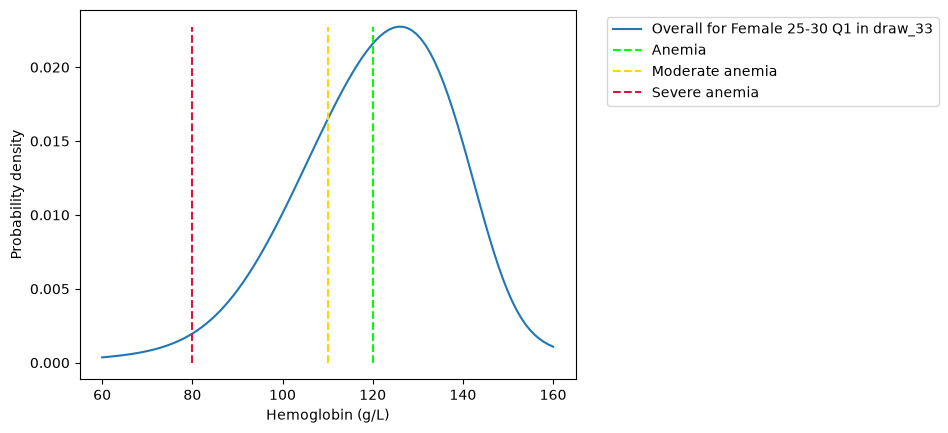

In [83]:
plot_example_distributions({"Overall": hemoglobin_distributions_by_age_sex_quintile})

In [84]:
# Assumption: non-iron-responsive anemias have same distribution of hemoglobin
# as iron-responsive anemias
non_iron_responsive_hemoglobin_distributions = truncate_distributions(
    hemoglobin_distributions_by_age_sex_quintile,
    truncate_max=hgb_info.hgb_upper_mild,
)

In [85]:
# Use even more wiggle room, as the issues in the previous check are "magnified"!
# NOTE: max_tolerance raised from 0.10 to 0.15 for model2.6.2.
# With the new GBD hemoglobin draws (release_id=33, from #72), India/rice max error went from 0.090 to 0.123.
# TODO: Check with research why the error increased for India/rice, then revisit this tolerance.
test_pdfs_cdfs_consistency(
    non_iron_responsive_hemoglobin_distributions,
    mean_tolerance=0.01,
    max_tolerance=0.15,
)

count    3.069000e+03
mean     2.370617e-03
std      7.854928e-03
min     -4.380811e-07
25%      1.141037e-05
50%      1.447431e-04
75%      8.071789e-04
max      5.814230e-02
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    0.500000   1.0      3                draw_127   -4.380811e-07
Female  0.076712   0.5      1                draw_183   -3.534032e-07
        0.500000   1.0      3                draw_1     -3.531995e-07
                            4                draw_122   -3.293735e-07
Male    1.000000   2.0      5                draw_231   -2.911988e-07
                                                             ...     
        90.000000  95.0     1                draw_111    5.648216e-02
        95.000000  125.0    1                draw_5      5.648559e-02
        90.000000  95.0     1                draw_116    5.649805e-02
        95.000000  125.0    1                draw_218    5.718074e-02
        90.000000  95.0     1                draw_165    5.814230e-02
Length: 3069, dtype: float64

count    3069.000000
mean        0.002320
std         0.007868
min        -0.000282
25%        -0.000015
50%         0.000087
75%         0.000757
max         0.058147
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    1.000000   2.0      3                draw_19    -0.000282
Female  0.500000   1.0      3                draw_1     -0.000267
        0.076712   0.5      1                draw_183   -0.000247
Male    0.500000   1.0      3                draw_127   -0.000238
Female  0.500000   1.0      4                draw_231   -0.000225
                                                           ...   
Male    90.000000  95.0     1                draw_111    0.056487
        95.000000  125.0    1                draw_5      0.056490
        90.000000  95.0     1                draw_116    0.056503
        95.000000  125.0    1                draw_218    0.057185
        90.000000  95.0     1                draw_165    0.058147
Length: 3069, dtype: float64

count    3069.000000
mean       -0.000193
std         0.008858
min        -0.017157
25%        -0.004205
50%        -0.001462
75%         0.000102
max         0.058151
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    10.0       15.0     5                draw_215   -0.017157
        5.0        10.0     3                draw_98    -0.015957
        10.0       15.0     5                draw_26    -0.015709
Female  10.0       15.0     5                draw_19    -0.014915
        5.0        10.0     5                draw_74    -0.014448
                                                           ...   
Male    90.0       95.0     1                draw_111    0.056492
        95.0       125.0    1                draw_5      0.056495
        90.0       95.0     1                draw_116    0.056507
        95.0       125.0    1                draw_218    0.057190
        90.0       95.0     1                draw_165    0.058151
Length: 3069, dtype: float64

count    3069.000000
mean       -0.002807
std         0.009353
min        -0.046249
25%        -0.006313
50%        -0.004175
75%        -0.001850
max         0.056723
dtype: float64


sex   age_start  age_end     wealth_quintile  draw    
Male  40.0       45.000000   5                draw_15    -0.046249
      45.0       50.000000   3                draw_1     -0.043068
                             4                draw_40    -0.042882
      50.0       55.000000   4                draw_21    -0.037629
      0.0        0.019178    5                draw_34    -0.037462
                                                            ...   
      90.0       95.000000   1                draw_111    0.055005
      95.0       125.000000  1                draw_5      0.055008
      90.0       95.000000   1                draw_116    0.055027
      95.0       125.000000  1                draw_218    0.055728
      90.0       95.000000   1                draw_165    0.056723
Length: 3069, dtype: float64

count    3069.000000
mean       -0.002807
std         0.009353
min        -0.046249
25%        -0.006313
50%        -0.004175
75%        -0.001850
max         0.056723
dtype: float64


sex   age_start  age_end     wealth_quintile  draw    
Male  40.0       45.000000   5                draw_15    -0.046249
      45.0       50.000000   3                draw_1     -0.043068
                             4                draw_40    -0.042882
      50.0       55.000000   4                draw_21    -0.037629
      0.0        0.019178    5                draw_34    -0.037462
                                                            ...   
      90.0       95.000000   1                draw_111    0.055005
      95.0       125.000000  1                draw_5      0.055008
      90.0       95.000000   1                draw_116    0.055027
      95.0       125.000000  1                draw_218    0.055728
      90.0       95.000000   1                draw_165    0.056723
Length: 3069, dtype: float64

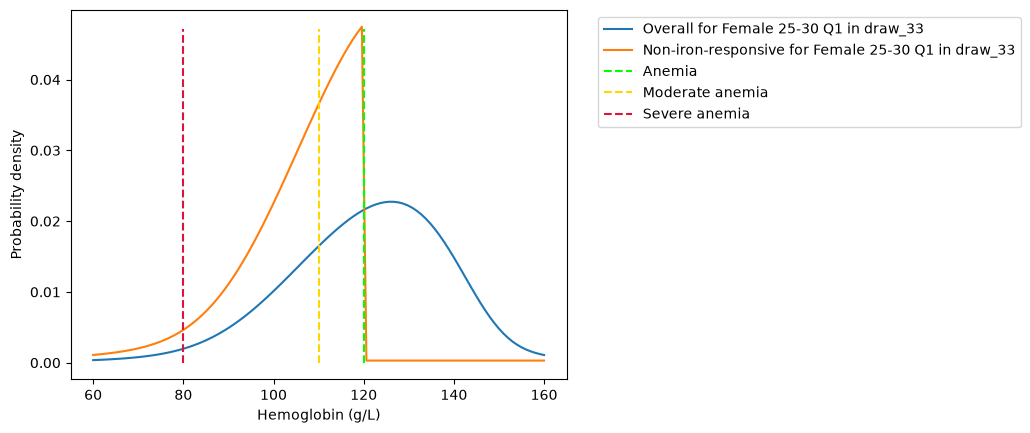

In [86]:
plot_example_distributions(
    {
        "Overall": hemoglobin_distributions_by_age_sex_quintile,
        "Non-iron-responsive": non_iron_responsive_hemoglobin_distributions,
    }
)

In [87]:
gbd_hemoglobin_distributions = distributions_from_mean_sd(
    gbd_hgb_mean, gbd_hgb_sd.loc[gbd_hgb_mean.index]
)

In [88]:
gbd_anemia_prevalence = gbd_hemoglobin_distributions.cdfs(
    thresholds.hgb_upper_mild.reindex(gbd_hgb_mean.index)
)
gbd_anemia_prevalence

sex     age_start  age_end     draw    
Female  0.0        0.019178    draw_0      0.757691
                               draw_1      0.799261
                               draw_2      0.804278
                               draw_3      0.820014
                               draw_4      0.810775
                                             ...   
Male    95.0       125.000000  draw_245    0.830798
                               draw_246    0.680520
                               draw_247    0.681934
                               draw_248    0.922294
                               draw_249    0.714759
Length: 12500, dtype: float64

In [89]:
non_iron_responsive_anemia_proportion = (
    non_iron_responsive_prevalence / gbd_anemia_prevalence
)
non_iron_responsive_anemia_proportion

sex     age_start  age_end     draw    
Female  0.0        0.019178    draw_0      0.088079
                               draw_1      0.102700
                               draw_2      0.083970
                               draw_3      0.074116
                               draw_4      0.090777
                                             ...   
Male    95.0       125.000000  draw_245    0.118084
                               draw_246    0.141460
                               draw_247    0.126960
                               draw_248    0.123601
                               draw_249    0.136514
Length: 12500, dtype: float64

In [90]:
non_iron_responsive_anemia_proportion

sex     age_start  age_end     draw    
Female  0.0        0.019178    draw_0      0.088079
                               draw_1      0.102700
                               draw_2      0.083970
                               draw_3      0.074116
                               draw_4      0.090777
                                             ...   
Male    95.0       125.000000  draw_245    0.118084
                               draw_246    0.141460
                               draw_247    0.126960
                               draw_248    0.123601
                               draw_249    0.136514
Length: 12500, dtype: float64

In [91]:
hemoglobin_distributions_by_age_sex_quintile.cdfs(hgb_info.hgb_upper_mild)

sex     age_start  age_end     wealth_quintile  draw    
Female  0.0        0.019178    1                draw_0      0.791393
                                                draw_1      0.812404
                                                draw_2      0.824752
                                                draw_3      0.847443
                                                draw_4      0.830915
                                                              ...   
Male    95.0       125.000000  5                draw_245    0.848339
                                                draw_246    0.691419
                                                draw_247    0.692846
                                                draw_248    0.938238
                                                draw_249    0.726576
Length: 62500, dtype: float64

In [92]:
non_iron_responsive_anemia_prevalence_by_age_sex_quintile = (
    (
        non_iron_responsive_anemia_proportion
        * hemoglobin_distributions_by_age_sex_quintile.cdfs(hgb_info.hgb_upper_mild)
    )
    .reorder_levels(hgb_info.index.names)
    .reindex(hgb_info.index)
)
non_iron_responsive_anemia_prevalence_by_age_sex_quintile

sex     age_start  age_end     wealth_quintile  draw    
Female  0.0        0.019178    1                draw_0      0.069705
                                                draw_1      0.083434
                                                draw_2      0.069255
                                                draw_3      0.062809
                                                draw_4      0.075428
                                                              ...   
Male    95.0       125.000000  5                draw_245    0.100175
                                                draw_246    0.097808
                                                draw_247    0.087964
                                                draw_248    0.115968
                                                draw_249    0.099188
Length: 62500, dtype: float64

In [93]:
iron_responsive_distributions = delete_from_mixture_distributions(
    hemoglobin_distributions_by_age_sex_quintile,
    non_iron_responsive_hemoglobin_distributions,
    non_iron_responsive_anemia_prevalence_by_age_sex_quintile,
)

In [94]:
test_pdfs_cdfs_consistency(
    iron_responsive_distributions,
    mean_tolerance=0.005,
    max_tolerance=0.05,
)

count    3.069000e+03
mean     1.302108e-03
std      4.716318e-03
min     -4.167413e-07
25%      5.286407e-06
50%      5.864243e-05
75%      3.238547e-04
max      3.755705e-02
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    0.500000   1.0      3                draw_127   -4.167413e-07
Female  0.500000   1.0      3                draw_1     -3.376579e-07
        0.076712   0.5      1                draw_183   -3.299447e-07
        0.500000   1.0      4                draw_122   -3.017927e-07
Male    0.500000   1.0      5                draw_192   -2.556949e-07
                                                             ...     
        90.000000  95.0     1                draw_111    3.513824e-02
        95.000000  125.0    1                draw_218    3.522431e-02
                                             draw_5      3.535817e-02
        90.000000  95.0     1                draw_116    3.540560e-02
                                             draw_165    3.755705e-02
Length: 3069, dtype: float64

count    3069.000000
mean        0.001277
std         0.004723
min        -0.000272
25%        -0.000008
50%         0.000031
75%         0.000304
max         0.037560
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    1.000000   2.0      3                draw_19    -0.000272
Female  0.500000   1.0      3                draw_1     -0.000255
        0.076712   0.5      1                draw_183   -0.000231
Male    0.500000   1.0      3                draw_127   -0.000227
Female  0.500000   1.0      4                draw_122   -0.000206
                                                           ...   
Male    90.000000  95.0     1                draw_111    0.035141
        95.000000  125.0    1                draw_218    0.035227
                                             draw_5      0.035361
        90.000000  95.0     1                draw_116    0.035408
                                             draw_165    0.037560
Length: 3069, dtype: float64

count    3069.000000
mean        0.001705
std         0.004646
min        -0.000837
25%         0.000223
50%         0.000650
75%         0.001078
max         0.037563
dtype: float64


sex   age_start  age_end     wealth_quintile  draw    
Male  0.019178   0.076712    4                draw_98    -0.000837
      50.000000  55.000000   2                draw_21    -0.000548
                             4                draw_21    -0.000457
      0.019178   0.076712    5                draw_97    -0.000402
      50.000000  55.000000   3                draw_219   -0.000386
                                                            ...   
      90.000000  95.000000   1                draw_111    0.035144
      95.000000  125.000000  1                draw_218    0.035230
                                              draw_5      0.035364
      90.000000  95.000000   1                draw_116    0.035411
                                              draw_165    0.037563
Length: 3069, dtype: float64

count    3069.000000
mean        0.001948
std         0.004634
min         0.000022
25%         0.000583
50%         0.000810
75%         0.001224
max         0.037701
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    80.0       85.000000   3                draw_19     0.000022
        75.0       80.000000   3                draw_99     0.000036
        1.0        2.000000    3                draw_19     0.000080
        0.0        0.019178    2                draw_214    0.000083
Female  0.5        1.000000    4                draw_134    0.000098
                                                              ...   
Male    90.0       95.000000   1                draw_111    0.035301
        95.0       125.000000  1                draw_218    0.035451
                                                draw_5      0.035505
        90.0       95.000000   1                draw_116    0.035563
                                                draw_165    0.037701
Length: 3069, dtype: float64

count    3069.000000
mean        0.001927
std         0.004636
min         0.000022
25%         0.000567
50%         0.000785
75%         0.001191
max         0.037698
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    80.0       85.000000   3                draw_19     0.000022
        75.0       80.000000   3                draw_99     0.000036
        0.0        0.019178    2                draw_214    0.000054
        1.0        2.000000    3                draw_19     0.000080
Female  0.5        1.000000    4                draw_134    0.000098
                                                              ...   
Male    90.0       95.000000   1                draw_111    0.035299
        95.0       125.000000  1                draw_218    0.035448
                                                draw_5      0.035503
        90.0       95.000000   1                draw_116    0.035561
                                                draw_165    0.037698
Length: 3069, dtype: float64

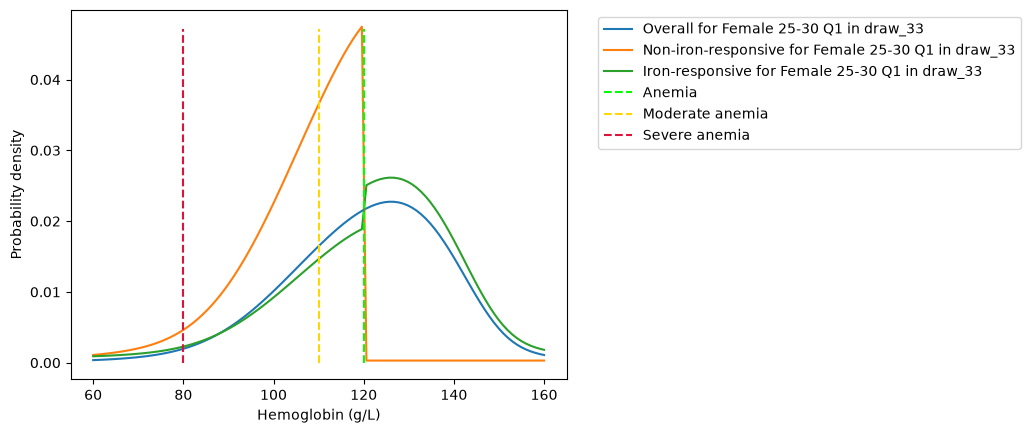

In [95]:
plot_example_distributions(
    {
        "Overall": hemoglobin_distributions_by_age_sex_quintile,
        "Non-iron-responsive": non_iron_responsive_hemoglobin_distributions,
        "Iron-responsive": iron_responsive_distributions,
    }
)

In [96]:
# NOTE: this decomposition, like what we do for wealth quintile above,
# is not exact -- we pretend that these two distributions would mix
# to the overall iron-responsive distribution, but they wouldn't.
# Here, we delete baseline coverage baked into the GBD 2021 distribution
# to get the without-fortification distribution.
# Also note that this and the next shift both assume that the hemoglobin effect among
# the responsive is a fixed value without individual-level variation.
iron_responsive_without_fortification_distributions = shift_distributions(
    iron_responsive_distributions,
    -effective_coverage_2021 * hemoglobin_effect_among_responsive.align(hgb_info)[0],
)

In [97]:
test_pdfs_cdfs_consistency(
    iron_responsive_without_fortification_distributions,
    mean_tolerance=0.005,
    max_tolerance=0.05,
)

count    3.069000e+03
mean     1.315811e-03
std      4.753917e-03
min     -4.417873e-07
25%      5.483353e-06
50%      6.026139e-05
75%      3.303185e-04
max      3.775212e-02
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    0.500000   1.0      3                draw_127   -4.417873e-07
Female  0.500000   1.0      3                draw_1     -3.601972e-07
        0.076712   0.5      1                draw_183   -3.430721e-07
        0.500000   1.0      4                draw_122   -3.213699e-07
Male    0.500000   1.0      5                draw_192   -2.732208e-07
                                                             ...     
        90.000000  95.0     1                draw_111    3.532172e-02
        95.000000  125.0    1                draw_218    3.540946e-02
                                             draw_5      3.554262e-02
        90.000000  95.0     1                draw_116    3.559034e-02
                                             draw_165    3.775212e-02
Length: 3069, dtype: float64

count    3069.000000
mean        0.001290
std         0.004761
min        -0.000281
25%        -0.000008
50%         0.000032
75%         0.000309
max         0.037755
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    1.000000   2.0      3                draw_19    -0.000281
Female  0.500000   1.0      3                draw_1     -0.000261
        0.076712   0.5      1                draw_183   -0.000234
Male    0.500000   1.0      3                draw_127   -0.000229
Female  0.500000   1.0      4                draw_122   -0.000210
                                                           ...   
Male    90.000000  95.0     1                draw_111    0.035325
        95.000000  125.0    1                draw_218    0.035412
                                             draw_5      0.035546
        90.000000  95.0     1                draw_116    0.035593
                                             draw_165    0.037755
Length: 3069, dtype: float64

count    3069.000000
mean        0.001296
std         0.005581
min        -0.016113
25%        -0.001609
50%         0.000133
75%         0.002513
max         0.037758
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  5.0        10.0     5                draw_115   -0.016113
                                             draw_202   -0.015157
                            4                draw_231   -0.015140
Male    5.0        10.0     4                draw_214   -0.013203
                                             draw_80    -0.012114
                                                           ...   
        90.0       95.0     1                draw_111    0.035328
        95.0       125.0    1                draw_218    0.035415
                                             draw_5      0.035548
        90.0       95.0     1                draw_116    0.035596
                                             draw_165    0.037758
Length: 3069, dtype: float64

count    3069.000000
mean        0.001154
std         0.005803
min        -0.016905
25%        -0.002218
50%         0.000946
75%         0.002754
max         0.038119
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  5.0        10.0     5                draw_115   -0.016905
                                             draw_202   -0.016019
                            4                draw_231   -0.015542
Male    5.0        10.0     4                draw_214   -0.013447
                                             draw_80    -0.012598
                                                           ...   
        90.0       95.0     1                draw_111    0.035741
        95.0       125.0    1                draw_5      0.035917
        90.0       95.0     1                draw_116    0.035993
        95.0       125.0    1                draw_218    0.036003
        90.0       95.0     1                draw_165    0.038119
Length: 3069, dtype: float64

count    3069.000000
mean        0.001133
std         0.005807
min        -0.016905
25%        -0.002254
50%         0.000946
75%         0.002734
max         0.038116
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  5.0        10.0     5                draw_115   -0.016905
                                             draw_202   -0.016019
                            4                draw_231   -0.015542
Male    5.0        10.0     4                draw_214   -0.013447
                                             draw_80    -0.012598
                                                           ...   
        90.0       95.0     1                draw_111    0.035740
        95.0       125.0    1                draw_5      0.035916
        90.0       95.0     1                draw_116    0.035991
        95.0       125.0    1                draw_218    0.036000
        90.0       95.0     1                draw_165    0.038116
Length: 3069, dtype: float64

In [98]:
iron_responsive_with_fortification_distributions = shift_distributions(
    iron_responsive_without_fortification_distributions,
    hemoglobin_effect_among_responsive.align(hgb_info)[0],
)

In [99]:
test_pdfs_cdfs_consistency(
    iron_responsive_with_fortification_distributions,
    mean_tolerance=0.005,
    max_tolerance=0.05,
)

count    3.069000e+03
mean     1.291042e-03
std      4.682762e-03
min     -2.612632e-07
25%      5.215481e-06
50%      5.796881e-05
75%      3.170228e-04
max      3.726299e-02
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    0.500000   1.0      3                draw_127   -2.612632e-07
Female  0.500000   1.0      3                draw_1     -2.417174e-07
        0.076712   0.5      1                draw_183   -2.255693e-07
Male    1.000000   2.0      3                draw_19    -1.769593e-07
                            5                draw_231   -1.695974e-07
                                                             ...     
        90.000000  95.0     1                draw_111    3.485607e-02
        95.000000  125.0    1                draw_218    3.493241e-02
                                             draw_5      3.507553e-02
        90.000000  95.0     1                draw_116    3.512399e-02
                                             draw_165    3.726299e-02
Length: 3069, dtype: float64

count    3069.000000
mean        0.001268
std         0.004689
min        -0.000229
25%        -0.000005
50%         0.000031
75%         0.000294
max         0.037266
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    1.000000   2.0      3                draw_19    -0.000229
Female  0.500000   1.0      3                draw_1     -0.000224
Male    0.500000   1.0      3                draw_127   -0.000212
Female  0.076712   0.5      1                draw_183   -0.000198
        0.500000   1.0      4                draw_122   -0.000186
                                                           ...   
Male    90.000000  95.0     1                draw_111    0.034859
        95.000000  125.0    1                draw_218    0.034935
                                             draw_5      0.035079
        90.000000  95.0     1                draw_116    0.035127
                                             draw_165    0.037266
Length: 3069, dtype: float64

count    3069.000000
mean        0.002684
std         0.004653
min        -0.000687
25%         0.000285
50%         0.001779
75%         0.002710
max         0.037269
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    0.019178   0.076712    4                draw_98    -0.000687
        50.000000  55.000000   2                draw_21    -0.000426
        0.019178   0.076712    4                draw_6     -0.000396
Female  0.019178   0.076712    3                draw_74    -0.000372
Male    0.019178   0.076712    3                draw_119   -0.000360
                                                              ...   
        90.000000  95.000000   1                draw_111    0.034862
        95.000000  125.000000  1                draw_218    0.034938
                                                draw_5      0.035081
        90.000000  95.000000   1                draw_116    0.035130
                                                draw_165    0.037269
Length: 3069, dtype: float64

count    3069.000000
mean        0.003247
std         0.004571
min        -0.003877
25%         0.001548
50%         0.002145
75%         0.002989
max         0.037506
dtype: float64


sex     age_start  age_end     wealth_quintile  draw    
Male    0.000000   0.019178    4                draw_91    -0.003877
        0.019178   0.076712    5                draw_144   -0.003678
        0.000000   0.019178    5                draw_34    -0.003267
Female  0.019178   0.076712    5                draw_48    -0.003027
Male    0.000000   0.019178    4                draw_181   -0.002358
                                                              ...   
        90.000000  95.000000   1                draw_111    0.035124
        95.000000  125.000000  1                draw_218    0.035289
                                                draw_5      0.035317
        90.000000  95.000000   1                draw_116    0.035386
                                                draw_165    0.037506
Length: 3069, dtype: float64

count    3069.000000
mean        0.003225
std         0.004577
min        -0.003849
25%         0.001526
50%         0.002129
75%         0.002981
max         0.037504
dtype: float64


sex   age_start  age_end     wealth_quintile  draw    
Male  0.000000   0.019178    4                draw_91    -0.003849
      0.019178   0.076712    5                draw_144   -0.003678
      0.000000   0.019178    3                draw_105   -0.003408
                             5                draw_34    -0.003400
                             4                draw_158   -0.003109
                                                            ...   
      90.000000  95.000000   1                draw_111    0.035123
      95.000000  125.000000  1                draw_218    0.035287
                                              draw_5      0.035316
      90.000000  95.000000   1                draw_116    0.035385
                                              draw_165    0.037504
Length: 3069, dtype: float64

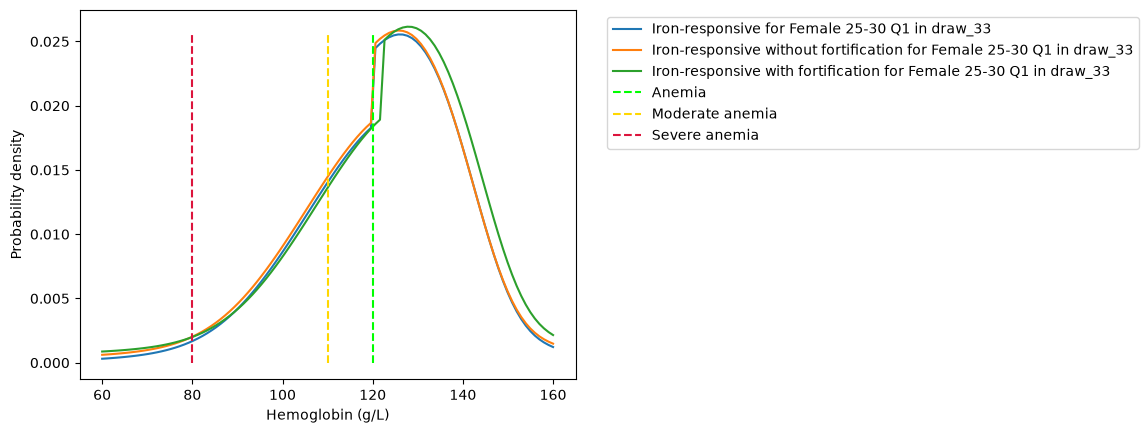

In [100]:
plot_example_distributions(
    {
        "Iron-responsive": iron_responsive_distributions,
        "Iron-responsive without fortification": iron_responsive_without_fortification_distributions,
        "Iron-responsive with fortification": iron_responsive_with_fortification_distributions,
    }
)

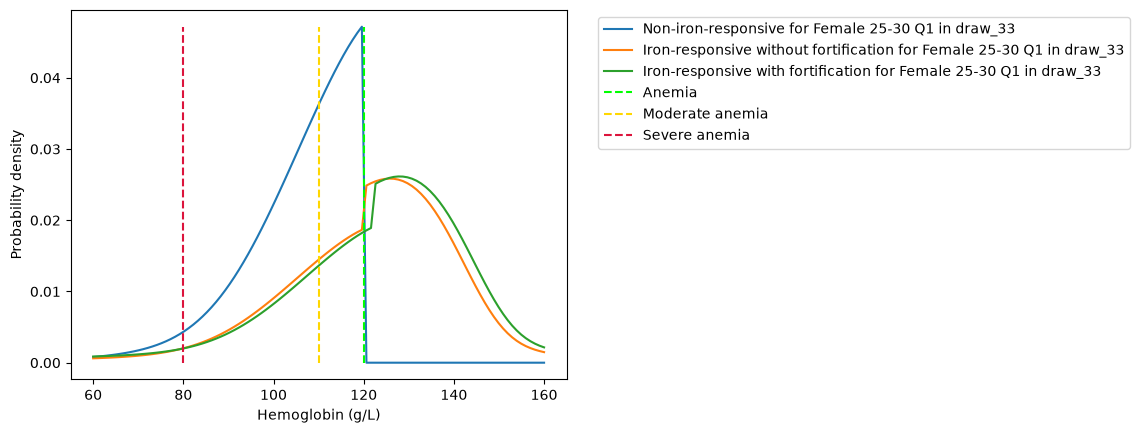

In [101]:
plot_example_distributions(
    {
        "Non-iron-responsive": non_iron_responsive_hemoglobin_distributions,
        "Iron-responsive without fortification": iron_responsive_without_fortification_distributions,
        "Iron-responsive with fortification": iron_responsive_with_fortification_distributions,
    }
)

In [102]:
zero_fort_scenario_distributions = mix_distributions(
    [
        (
            non_iron_responsive_hemoglobin_distributions,
            non_iron_responsive_anemia_prevalence_by_age_sex_quintile,
        ),
        (
            iron_responsive_without_fortification_distributions,
            1 - non_iron_responsive_anemia_prevalence_by_age_sex_quintile,
        ),
    ]
)

In [103]:
test_pdfs_cdfs_consistency(
    zero_fort_scenario_distributions,
    mean_tolerance=0.005,
    max_tolerance=0.05,
)

count    3.069000e+03
mean     1.427344e-03
std      5.074774e-03
min     -4.414051e-07
25%      6.195471e-06
50%      7.096571e-05
75%      3.909267e-04
max      3.946956e-02
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    0.500000   1.0      3                draw_127   -4.414051e-07
Female  0.500000   1.0      3                draw_1     -3.593070e-07
        0.076712   0.5      1                draw_183   -3.445068e-07
        0.500000   1.0      4                draw_122   -3.222686e-07
Male    0.500000   1.0      5                draw_192   -2.749327e-07
                                                             ...     
        90.000000  95.0     1                draw_111    3.726690e-02
        95.000000  125.0    1                draw_5      3.727403e-02
        90.000000  95.0     1                draw_116    3.745034e-02
        95.000000  125.0    1                draw_218    3.818613e-02
        90.000000  95.0     1                draw_165    3.946956e-02
Length: 3069, dtype: float64

count    3069.000000
mean        0.001398
std         0.005083
min        -0.000281
25%        -0.000009
50%         0.000039
75%         0.000364
max         0.039472
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    1.000000   2.0      3                draw_19    -0.000281
Female  0.500000   1.0      3                draw_1     -0.000262
        0.076712   0.5      1                draw_183   -0.000236
Male    0.500000   1.0      3                draw_127   -0.000230
Female  0.500000   1.0      4                draw_122   -0.000211
                                                           ...   
Male    90.000000  95.0     1                draw_111    0.037270
        95.000000  125.0    1                draw_5      0.037277
        90.000000  95.0     1                draw_116    0.037453
        95.000000  125.0    1                draw_218    0.038189
        90.000000  95.0     1                draw_165    0.039472
Length: 3069, dtype: float64

count    3069.000000
mean        0.001083
std         0.005731
min        -0.015281
25%        -0.001754
50%         0.000157
75%         0.001977
max         0.039476
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  5.0        10.0     5                draw_115   -0.015281
                                             draw_202   -0.014418
                            4                draw_231   -0.013798
Male    5.0        10.0     4                draw_214   -0.012440
        10.0       15.0     5                draw_215   -0.011180
                                                           ...   
        90.0       95.0     1                draw_111    0.037273
        95.0       125.0    1                draw_5      0.037280
        90.0       95.0     1                draw_116    0.037457
        95.0       125.0    1                draw_218    0.038192
        90.0       95.0     1                draw_165    0.039476
Length: 3069, dtype: float64

count    3069.000000
mean        0.000715
std         0.005917
min        -0.015925
25%        -0.002539
50%         0.000714
75%         0.002063
max         0.039686
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  5.0        10.0     5                draw_115   -0.015925
                                             draw_202   -0.015118
                            4                draw_231   -0.014114
Male    5.0        10.0     4                draw_214   -0.012639
        10.0       15.0     5                draw_215   -0.012370
                                                           ...   
        95.0       125.0    1                draw_5      0.037496
        90.0       95.0     1                draw_111    0.037512
                                             draw_116    0.037687
        95.0       125.0    1                draw_218    0.038518
        90.0       95.0     1                draw_165    0.039686
Length: 3069, dtype: float64

count    3069.000000
mean        0.000696
std         0.005921
min        -0.015925
25%        -0.002566
50%         0.000710
75%         0.002049
max         0.039683
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  5.0        10.0     5                draw_115   -0.015925
                                             draw_202   -0.015118
                            4                draw_231   -0.014114
Male    5.0        10.0     4                draw_214   -0.012639
        10.0       15.0     5                draw_215   -0.012370
                                                           ...   
        95.0       125.0    1                draw_5      0.037494
        90.0       95.0     1                draw_111    0.037511
                                             draw_116    0.037685
        95.0       125.0    1                draw_218    0.038516
        90.0       95.0     1                draw_165    0.039683
Length: 3069, dtype: float64

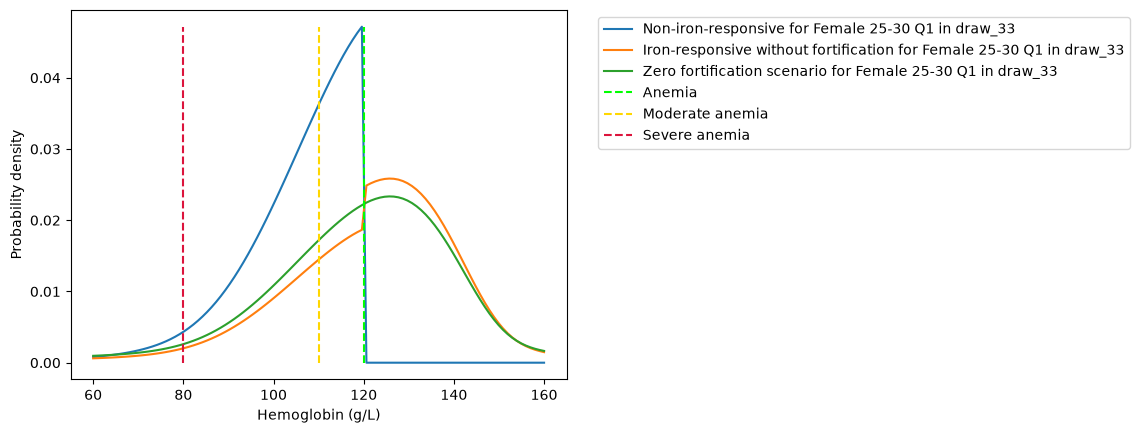

In [104]:
plot_example_distributions(
    {
        "Non-iron-responsive": non_iron_responsive_hemoglobin_distributions,
        "Iron-responsive without fortification": iron_responsive_without_fortification_distributions,
        "Zero fortification scenario": zero_fort_scenario_distributions,
    }
)

In [105]:
baseline_scenario_distributions = mix_distributions(
    [
        (
            non_iron_responsive_hemoglobin_distributions,
            non_iron_responsive_anemia_prevalence_by_age_sex_quintile,
        ),
        (
            iron_responsive_without_fortification_distributions,
            (1 - non_iron_responsive_anemia_prevalence_by_age_sex_quintile)
            * (1 - effective_coverage_baseline),
        ),
        (
            iron_responsive_with_fortification_distributions,
            (1 - non_iron_responsive_anemia_prevalence_by_age_sex_quintile)
            * effective_coverage_baseline,
        ),
    ]
)

In [106]:
test_pdfs_cdfs_consistency(
    baseline_scenario_distributions,
    mean_tolerance=0.005,
    max_tolerance=0.05,
)

count    3.069000e+03
mean     1.423637e-03
std      5.064532e-03
min     -4.105862e-07
25%      6.158160e-06
50%      7.046888e-05
75%      3.889251e-04
max      3.941617e-02
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    0.500000   1.0      3                draw_127   -4.105862e-07
Female  0.500000   1.0      3                draw_1     -3.396233e-07
        0.076712   0.5      1                draw_183   -3.324453e-07
        0.500000   1.0      4                draw_122   -2.942306e-07
Male    1.000000   2.0      5                draw_231   -2.553826e-07
                                                             ...     
        90.000000  95.0     1                draw_111    3.721650e-02
        95.000000  125.0    1                draw_5      3.722296e-02
        90.000000  95.0     1                draw_116    3.739969e-02
        95.000000  125.0    1                draw_218    3.813652e-02
        90.000000  95.0     1                draw_165    3.941617e-02
Length: 3069, dtype: float64

count    3069.000000
mean        0.001395
std         0.005072
min        -0.000272
25%        -0.000009
50%         0.000039
75%         0.000362
max         0.039419
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    1.000000   2.0      3                draw_19    -0.000272
Female  0.500000   1.0      3                draw_1     -0.000256
        0.076712   0.5      1                draw_183   -0.000232
Male    0.500000   1.0      3                draw_127   -0.000227
Female  0.500000   1.0      4                draw_122   -0.000207
                                                           ...   
Male    90.000000  95.0     1                draw_111    0.037220
        95.000000  125.0    1                draw_5      0.037226
        90.000000  95.0     1                draw_116    0.037403
        95.000000  125.0    1                draw_218    0.038140
        90.000000  95.0     1                draw_165    0.039419
Length: 3069, dtype: float64

count    3069.000000
mean        0.001355
std         0.005435
min        -0.009605
25%        -0.001060
50%         0.000158
75%         0.001883
max         0.039422
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  5.0        10.0     5                draw_115   -0.009605
                            4                draw_231   -0.009307
                            5                draw_202   -0.009039
Male    5.0        10.0     4                draw_214   -0.008461
                                             draw_80    -0.007470
                                                           ...   
        90.0       95.0     1                draw_111    0.037223
        95.0       125.0    1                draw_5      0.037229
        90.0       95.0     1                draw_116    0.037406
        95.0       125.0    1                draw_218    0.038143
        90.0       95.0     1                draw_165    0.039422
Length: 3069, dtype: float64

count    3069.000000
mean        0.001122
std         0.005570
min        -0.010195
25%        -0.001687
50%         0.000698
75%         0.001948
max         0.039619
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  5.0        10.0     5                draw_115   -0.010195
                                             draw_202   -0.009715
                            4                draw_231   -0.009685
Male    5.0        10.0     4                draw_214   -0.008630
        45.0       50.0     3                draw_1     -0.008110
                                                           ...   
        95.0       125.0    1                draw_5      0.037430
        90.0       95.0     1                draw_111    0.037445
                                             draw_116    0.037621
        95.0       125.0    1                draw_218    0.038444
        90.0       95.0     1                draw_165    0.039619
Length: 3069, dtype: float64

count    3069.000000
mean        0.001103
std         0.005575
min        -0.010195
25%        -0.001719
50%         0.000693
75%         0.001938
max         0.039616
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  5.0        10.0     5                draw_115   -0.010195
                                             draw_202   -0.009715
                            4                draw_231   -0.009685
Male    5.0        10.0     4                draw_214   -0.008630
        45.0       50.0     3                draw_1     -0.008110
                                                           ...   
        95.0       125.0    1                draw_5      0.037428
        90.0       95.0     1                draw_111    0.037444
                                             draw_116    0.037619
        95.0       125.0    1                draw_218    0.038442
        90.0       95.0     1                draw_165    0.039616
Length: 3069, dtype: float64

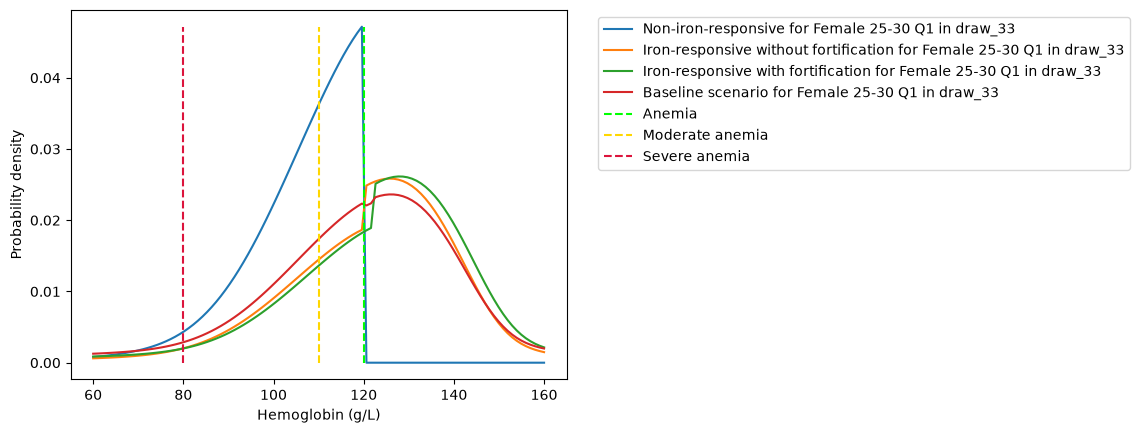

In [107]:
plot_example_distributions(
    {
        "Non-iron-responsive": non_iron_responsive_hemoglobin_distributions,
        "Iron-responsive without fortification": iron_responsive_without_fortification_distributions,
        "Iron-responsive with fortification": iron_responsive_with_fortification_distributions,
        "Baseline scenario": baseline_scenario_distributions,
    }
)

In [108]:
intervention_scenario_distributions = {}

for intervention_scenario in intervention_scenarios:
    effective_coverage_for_scenario = (
        effective_coverage_intervention[
            effective_coverage_intervention.index.get_level_values("scenario")
            == intervention_scenario
        ]
        .droplevel("scenario")
        .reindex(hgb_info.index)
    )
    intervention_scenario_distributions[intervention_scenario] = mix_distributions(
        [
            (
                non_iron_responsive_hemoglobin_distributions,
                non_iron_responsive_anemia_prevalence_by_age_sex_quintile,
            ),
            (
                iron_responsive_without_fortification_distributions,
                (1 - non_iron_responsive_anemia_prevalence_by_age_sex_quintile)
                * (1 - effective_coverage_for_scenario),
            ),
            (
                iron_responsive_with_fortification_distributions,
                (1 - non_iron_responsive_anemia_prevalence_by_age_sex_quintile)
                * effective_coverage_for_scenario,
            ),
        ]
    )

In [109]:
for _, dists in intervention_scenario_distributions.items():
    test_pdfs_cdfs_consistency(
        dists,
        mean_tolerance=0.005,
        max_tolerance=0.05,
    )

count    3.069000e+03
mean     1.422316e-03
std      5.060885e-03
min     -3.996087e-07
25%      6.144870e-06
50%      7.027548e-05
75%      3.882122e-04
max      3.939715e-02
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    0.500000   1.0      3                draw_127   -3.996087e-07
Female  0.500000   1.0      3                draw_1     -3.326122e-07
        0.076712   0.5      1                draw_183   -3.281490e-07
        0.500000   1.0      4                draw_122   -2.842436e-07
Male    1.000000   2.0      5                draw_231   -2.488684e-07
                                                             ...     
        90.000000  95.0     1                draw_111    3.719854e-02
        95.000000  125.0    1                draw_5      3.720476e-02
        90.000000  95.0     1                draw_116    3.738166e-02
        95.000000  125.0    1                draw_218    3.811885e-02
        90.000000  95.0     1                draw_165    3.939715e-02
Length: 3069, dtype: float64

count    3069.000000
mean        0.001394
std         0.005068
min        -0.000269
25%        -0.000009
50%         0.000039
75%         0.000361
max         0.039400
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Male    1.000000   2.0      3                draw_19    -0.000269
Female  0.500000   1.0      3                draw_1     -0.000254
        0.076712   0.5      1                draw_183   -0.000231
Male    0.500000   1.0      3                draw_127   -0.000226
Female  0.500000   1.0      4                draw_122   -0.000205
                                                           ...   
Male    90.000000  95.0     1                draw_111    0.037202
        95.000000  125.0    1                draw_5      0.037208
        90.000000  95.0     1                draw_116    0.037385
        95.000000  125.0    1                draw_218    0.038122
        90.000000  95.0     1                draw_165    0.039400
Length: 3069, dtype: float64

count    3069.000000
mean        0.001452
std         0.005344
min        -0.007707
25%        -0.000802
50%         0.000161
75%         0.001840
max         0.039403
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  5.0        10.0     4                draw_231   -0.007707
                            5                draw_115   -0.007583
                                             draw_202   -0.007123
Male    5.0        10.0     4                draw_214   -0.007043
                                             draw_80    -0.006166
                                                           ...   
        90.0       95.0     1                draw_111    0.037205
        95.0       125.0    1                draw_5      0.037211
        90.0       95.0     1                draw_116    0.037388
        95.0       125.0    1                draw_218    0.038125
        90.0       95.0     1                draw_165    0.039403
Length: 3069, dtype: float64

count    3069.000000
mean        0.001268
std         0.005461
min        -0.008154
25%        -0.001396
50%         0.000721
75%         0.001917
max         0.039595
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  5.0        10.0     5                draw_115   -0.008154
                            4                draw_231   -0.008107
                            5                draw_202   -0.007791
Male    5.0        10.0     4                draw_214   -0.007202
        45.0       50.0     3                draw_1     -0.006971
                                                           ...   
        95.0       125.0    1                draw_5      0.037407
        90.0       95.0     1                draw_111    0.037422
                                             draw_116    0.037597
        95.0       125.0    1                draw_218    0.038418
        90.0       95.0     1                draw_165    0.039595
Length: 3069, dtype: float64

count    3069.000000
mean        0.001249
std         0.005466
min        -0.008154
25%        -0.001420
50%         0.000706
75%         0.001903
max         0.039593
dtype: float64


sex     age_start  age_end  wealth_quintile  draw    
Female  5.0        10.0     5                draw_115   -0.008154
                            4                draw_231   -0.008107
                            5                draw_202   -0.007791
Male    5.0        10.0     4                draw_214   -0.007203
        45.0       50.0     3                draw_1     -0.006971
                                                           ...   
        95.0       125.0    1                draw_5      0.037405
        90.0       95.0     1                draw_111    0.037420
                                             draw_116    0.037595
        95.0       125.0    1                draw_218    0.038416
        90.0       95.0     1                draw_165    0.039593
Length: 3069, dtype: float64

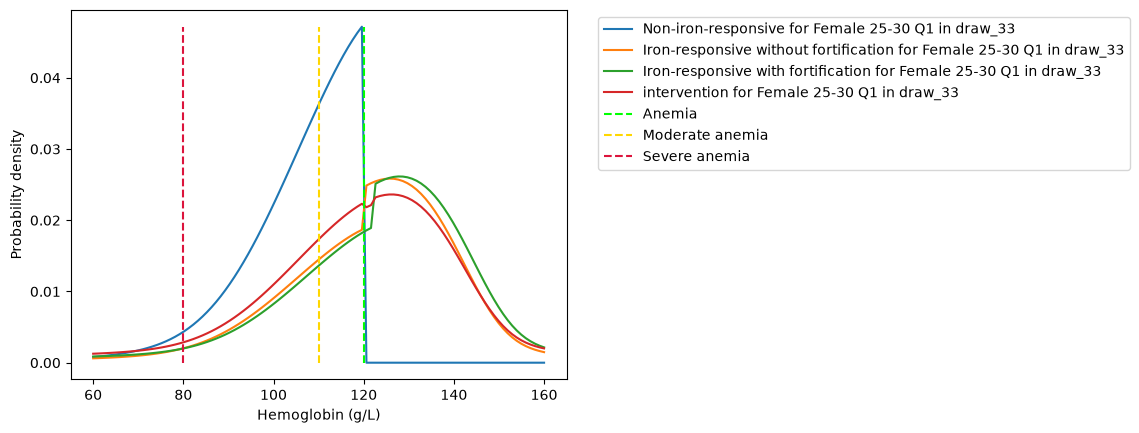

In [110]:
for intervention_scenario in intervention_scenarios:
    plot_example_distributions(
        {
            "Non-iron-responsive": non_iron_responsive_hemoglobin_distributions,
            "Iron-responsive without fortification": iron_responsive_without_fortification_distributions,
            "Iron-responsive with fortification": iron_responsive_with_fortification_distributions,
            intervention_scenario: intervention_scenario_distributions[
                intervention_scenario
            ],
        }
    )
    plt.show()

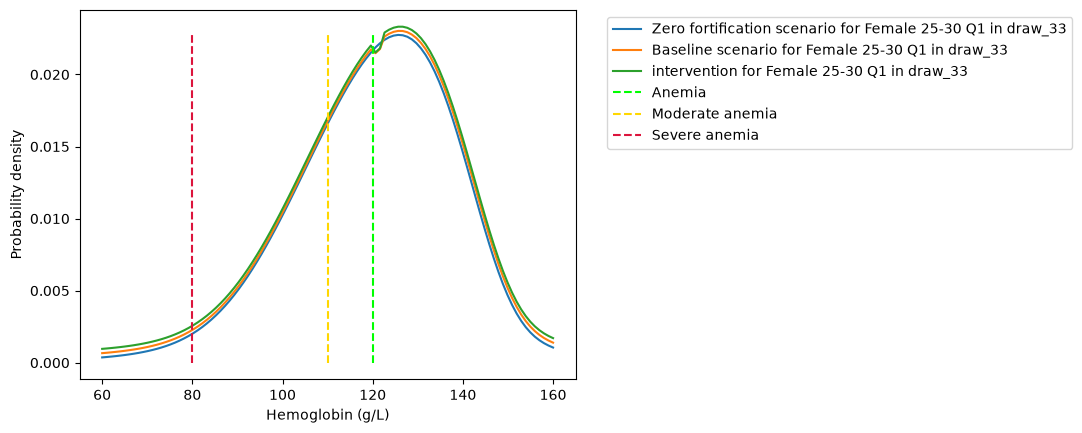

In [111]:
plot_example_distributions(
    {
        "Zero fortification scenario": zero_fort_scenario_distributions,
        "Baseline scenario": baseline_scenario_distributions,
        **intervention_scenario_distributions,
    }
)

In [112]:
def anemia_by_severity_from_distributions(distributions: Distributions):
    result = pd.DataFrame(index=distributions.data_index)
    assert result.index.equals(hgb_info.index)

    result["severe"] = distributions.cdfs(
        hgb_info.hgb_upper_severe.copy()
    ) - distributions.cdfs(hgb_info.hgb_lower_severe.copy())
    result["moderate"] = (
        distributions.cdfs(hgb_info.hgb_upper_moderate.copy()) - result["severe"]
    )
    result["mild"] = (
        distributions.cdfs(hgb_info.hgb_upper_mild.copy())
        - result["moderate"]
        - result["severe"]
    )
    result["anemic"] = result["mild"] + result["moderate"] + result["severe"]

    assert (result >= 0).all().all()
    assert (result <= 1).all().all()
    return result

In [113]:
zero_fort_scenario_anemia_by_severity = anemia_by_severity_from_distributions(
    zero_fort_scenario_distributions
)
zero_fort_scenario_anemia_by_severity

severe  moderate  \
sex    age_start age_end    wealth_quintile draw                           
Female 0.0       0.019178   1               draw_0    0.045312  0.489615   
                                            draw_1    0.160964  0.481392   
                                            draw_2    0.092295  0.521295   
                                            draw_3    0.046766  0.543295   
                                            draw_4    0.091062  0.527516   
...                                                        ...       ...   
Male   95.0      125.000000 5               draw_245  0.128484  0.404394   
                                            draw_246  0.277564  0.254229   
                                            draw_247  0.263697  0.260456   
                                            draw_248  0.176583  0.491852   
                                            draw_249  0.158331  0.315751   

                                                          mild    anemic  
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0    0.260412  0.795339  
                                            draw_1    0.172631  0.814988  
                                            draw_2    0.214271  0.827861  
                                            draw_3    0.260952  0.851012  
                                            draw_4    0.215424  0.834002  
...                                                        ...       ...  
Male   95.0      125.000000 5               draw_245  0.321361  0.854239  
                                            draw_246  0.163364  0.695157  
                                            draw_247  0.172648  0.696802  
                                            draw_248  0.273060  0.941495  
                                            draw_249  0.258276  0.732358  

[62500 rows x 4 columns]

In [114]:
baseline_scenario_anemia_by_severity = anemia_by_severity_from_distributions(
    baseline_scenario_distributions
)
baseline_scenario_anemia_by_severity

severe  moderate  \
sex    age_start age_end    wealth_quintile draw                           
Female 0.0       0.019178   1               draw_0    0.044624  0.486089   
                                            draw_1    0.159631  0.479836   
                                            draw_2    0.091129  0.518770   
                                            draw_3    0.046000  0.539448   
                                            draw_4    0.089903  0.524969   
...                                                        ...       ...   
Male   95.0      125.000000 5               draw_245  0.125461  0.400168   
                                            draw_246  0.279066  0.249402   
                                            draw_247  0.264472  0.256110   
                                            draw_248  0.172404  0.488225   
                                            draw_249  0.156158  0.312756   

                                                          mild    anemic  
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0    0.260880  0.791592  
                                            draw_1    0.173113  0.812581  
                                            draw_2    0.214988  0.824887  
                                            draw_3    0.262068  0.847516  
                                            draw_4    0.216190  0.831063  
...                                                        ...       ...  
Male   95.0      125.000000 5               draw_245  0.323047  0.848675  
                                            draw_246  0.163347  0.691816  
                                            draw_247  0.172637  0.693219  
                                            draw_248  0.277670  0.938299  
                                            draw_249  0.258221  0.727135  

[62500 rows x 4 columns]

In [115]:
intervention_scenarios_anemia_by_severity = {}

for scenario, distributions in intervention_scenario_distributions.items():
    anemia_by_severity = anemia_by_severity_from_distributions(distributions)
    print(scenario)
    display(anemia_by_severity)
    intervention_scenarios_anemia_by_severity[scenario] = anemia_by_severity

intervention


severe  moderate  \
sex    age_start age_end    wealth_quintile draw                           
Female 0.0       0.019178   1               draw_0    0.044379  0.484833   
                                            draw_1    0.159157  0.479282   
                                            draw_2    0.090714  0.517871   
                                            draw_3    0.045727  0.538078   
                                            draw_4    0.089490  0.524062   
...                                                        ...       ...   
Male   95.0      125.000000 5               draw_245  0.124384  0.398662   
                                            draw_246  0.279602  0.247683   
                                            draw_247  0.264749  0.254561   
                                            draw_248  0.170916  0.486933   
                                            draw_249  0.155384  0.311689   

                                                          mild    anemic  
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0    0.261046  0.790258  
                                            draw_1    0.173284  0.811723  
                                            draw_2    0.215243  0.823827  
                                            draw_3    0.262465  0.846270  
                                            draw_4    0.216463  0.830016  
...                                                        ...       ...  
Male   95.0      125.000000 5               draw_245  0.323648  0.846694  
                                            draw_246  0.163341  0.690626  
                                            draw_247  0.172633  0.691943  
                                            draw_248  0.279311  0.937160  
                                            draw_249  0.258202  0.725275  

[62500 rows x 4 columns]

In [116]:
# Transform the intervention scenarios back from a dictionary to the scenario being a level
# in the MultiIndex, which is easier to work with now that we are out of function/distribution space.
intervention_scenarios_anemia_by_severity = pd.concat(
    [
        anemia_by_severity.assign(scenario=scenario).set_index("scenario", append=True)
        for scenario, anemia_by_severity in intervention_scenarios_anemia_by_severity.items()
    ]
)
intervention_scenarios_anemia_by_severity

severe  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention  0.044379   
                                            draw_1   intervention  0.159157   
                                            draw_2   intervention  0.090714   
                                            draw_3   intervention  0.045727   
                                            draw_4   intervention  0.089490   
...                                                                     ...   
Male   95.0      125.000000 5               draw_245 intervention  0.124384   
                                            draw_246 intervention  0.279602   
                                            draw_247 intervention  0.264749   
                                            draw_248 intervention  0.170916   
                                            draw_249 intervention  0.155384   

                                                                   moderate  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention  0.484833   
                                            draw_1   intervention  0.479282   
                                            draw_2   intervention  0.517871   
                                            draw_3   intervention  0.538078   
                                            draw_4   intervention  0.524062   
...                                                                     ...   
Male   95.0      125.000000 5               draw_245 intervention  0.398662   
                                            draw_246 intervention  0.247683   
                                            draw_247 intervention  0.254561   
                                            draw_248 intervention  0.486933   
                                            draw_249 intervention  0.311689   

                                                                       mild  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention  0.261046   
                                            draw_1   intervention  0.173284   
                                            draw_2   intervention  0.215243   
                                            draw_3   intervention  0.262465   
                                            draw_4   intervention  0.216463   
...                                                                     ...   
Male   95.0      125.000000 5               draw_245 intervention  0.323648   
                                            draw_246 intervention  0.163341   
                                            draw_247 intervention  0.172633   
                                            draw_248 intervention  0.279311   
                                            draw_249 intervention  0.258202   

                                                                     anemic  
sex    age_start age_end    wealth_quintile draw     scenario                
Female 0.0       0.019178   1               draw_0   intervention  0.790258  
                                            draw_1   intervention  0.811723  
                                            draw_2   intervention  0.823827  
                                            draw_3   intervention  0.846270  
                                            draw_4   intervention  0.830016  
...                                                                     ...  
Male   95.0      125.000000 5               draw_245 intervention  0.846694  
                                            draw_246 intervention  0.690626  
                                            draw_247 intervention  0.691943  
                                            draw_248 intervention  0.937160  
                                            draw_

In [117]:
zero_fort_scenario_anemia_by_severity - baseline_scenario_anemia_by_severity

severe  moderate  \
sex    age_start age_end    wealth_quintile draw                           
Female 0.0       0.019178   1               draw_0    0.000688  0.003526   
                                            draw_1    0.001333  0.001556   
                                            draw_2    0.001166  0.002525   
                                            draw_3    0.000766  0.003847   
                                            draw_4    0.001159  0.002546   
...                                                        ...       ...   
Male   95.0      125.000000 5               draw_245  0.003023  0.004227   
                                            draw_246 -0.001502  0.004827   
                                            draw_247 -0.000775  0.004346   
                                            draw_248  0.004179  0.003627   
                                            draw_249  0.002172  0.002995   

                                                          mild    anemic  
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0   -0.000468  0.003747  
                                            draw_1   -0.000482  0.002407  
                                            draw_2   -0.000716  0.002974  
                                            draw_3   -0.001116  0.003497  
                                            draw_4   -0.000766  0.002939  
...                                                        ...       ...  
Male   95.0      125.000000 5               draw_245 -0.001686  0.005563  
                                            draw_246  0.000017  0.003341  
                                            draw_247  0.000011  0.003582  
                                            draw_248 -0.004609  0.003197  
                                            draw_249  0.000055  0.005222  

[62500 rows x 4 columns]

In [118]:
baseline_scenario_anemia_by_severity - intervention_scenarios_anemia_by_severity

severe  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention  0.000245   
                                            draw_1   intervention  0.000475   
                                            draw_10  intervention  0.000595   
                                            draw_100 intervention  0.000302   
                                            draw_101 intervention  0.000307   
...                                                                     ...   
Male   95.0      125.000000 5               draw_95  intervention  0.001141   
                                            draw_96  intervention  0.000473   
                                            draw_97  intervention -0.000352   
                                            draw_98  intervention  0.000514   
                                            draw_99  intervention -0.000650   

                                                                   moderate  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention  0.001256   
                                            draw_1   intervention  0.000554   
                                            draw_10  intervention  0.000479   
                                            draw_100 intervention  0.001128   
                                            draw_101 intervention  0.001061   
...                                                                     ...   
Male   95.0      125.000000 5               draw_95  intervention  0.000929   
                                            draw_96  intervention  0.001028   
                                            draw_97  intervention  0.001460   
                                            draw_98  intervention  0.001066   
                                            draw_99  intervention  0.001791   

                                                                       mild  \
sex    age_start age_end    wealth_quintile draw     scenario                 
Female 0.0       0.019178   1               draw_0   intervention -0.000167   
                                            draw_1   intervention -0.000172   
                                            draw_10  intervention -0.000318   
                                            draw_100 intervention -0.000274   
                                            draw_101 intervention -0.000252   
...                                                                     ...   
Male   95.0      125.000000 5               draw_95  intervention -0.000589   
                                            draw_96  intervention  0.000129   
                                            draw_97  intervention  0.000071   
                                            draw_98  intervention  0.000022   
                                            draw_99  intervention -0.000021   

                                                                     anemic  
sex    age_start age_end    wealth_quintile draw     scenario                
Female 0.0       0.019178   1               draw_0   intervention  0.001335  
                                            draw_1   intervention  0.000857  
                                            draw_10  intervention  0.000756  
                                            draw_100 intervention  0.001156  
                                            draw_101 intervention  0.001116  
...                                                                     ...  
Male   95.0      125.000000 5               draw_95  intervention  0.001480  
                                            draw_96  intervention  0.001630  
                                            draw_97  intervention  0.001179  
                                            draw_98  intervention  0.001602  
                                            draw_

<Axes: >

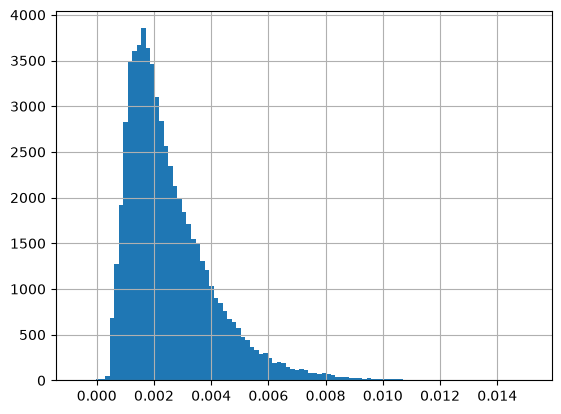

In [119]:
# We can see that in very rare cases, likely due to numerical instability, we get a negative impact
(
    baseline_scenario_anemia_by_severity - intervention_scenarios_anemia_by_severity
).anemic.hist(bins=100)

In [120]:
def anemia_by_severity_to_yld_rates(anemia_by_severity):
    disability_weights = pd.read_hdf(
        "/mnt/team/simulation_science/costeffectiveness/auxiliary_data/GBD_2021/02_processed_data/disability_weight/sequela/all/all.hdf"
    )
    disability_weights = (
        disability_weights[
            disability_weights.healthstate.isin(
                ["anemia_mild", "anemia_mod", "anemia_sev"]
            )
        ]
        .set_index("healthstate")
        .filter(like="draw_")
    )
    disability_weights.columns.name = "draw"
    disability_weights = (
        disability_weights.stack().rename("disability_weight").reset_index()
    )
    display(disability_weights)

    orig_index = anemia_by_severity.index
    anemia_by_severity = (
        anemia_by_severity.reset_index()
        .merge(
            disability_weights[disability_weights.healthstate == "anemia_mild"][
                ["draw", "disability_weight"]
            ].rename(columns={"disability_weight": "mild_dw"}),
            validate="m:1",
        )
        .merge(
            disability_weights[disability_weights.healthstate == "anemia_mod"][
                ["draw", "disability_weight"]
            ].rename(columns={"disability_weight": "moderate_dw"}),
            validate="m:1",
        )
        .merge(
            disability_weights[disability_weights.healthstate == "anemia_sev"][
                ["draw", "disability_weight"]
            ].rename(columns={"disability_weight": "severe_dw"}),
            validate="m:1",
        )
    )

    anemia_by_severity["mild_yld_rate"] = (
        anemia_by_severity.mild * anemia_by_severity.mild_dw
    )
    anemia_by_severity["moderate_yld_rate"] = (
        anemia_by_severity.moderate * anemia_by_severity.moderate_dw
    )
    anemia_by_severity["severe_yld_rate"] = (
        anemia_by_severity.severe * anemia_by_severity.severe_dw
    )
    anemia_by_severity["anemic_yld_rate"] = (
        anemia_by_severity["mild_yld_rate"]
        + anemia_by_severity["moderate_yld_rate"]
        + anemia_by_severity["severe_yld_rate"]
    )

    return anemia_by_severity.set_index(orig_index.names).filter(like="yld_rate")

In [121]:
zero_fort_scenario_anemia_yld_rates = anemia_by_severity_to_yld_rates(
    zero_fort_scenario_anemia_by_severity
)
zero_fort_scenario_anemia_yld_rates

,healthstate,draw,disability_weight
0,anemia_mild,draw_0,0.002420
1,anemia_mild,draw_1,0.003172
2,anemia_mild,draw_2,0.002644
3,anemia_mild,draw_3,0.003085
4,anemia_mild,draw_4,0.001845
...,...,...,...
2995,anemia_sev,draw_995,0.174969
2996,anemia_sev,draw_996,0.086798
2997,anemia_sev,draw_997,0.131996
2998,anemia_sev,draw_998,0.124427


mild_yld_rate  \
sex    age_start age_end    wealth_quintile draw                      
Female 0.0       0.019178   1               draw_0         0.000630   
                                            draw_1         0.000548   
                                            draw_2         0.000566   
                                            draw_3         0.000805   
                                            draw_4         0.000397   
...                                                             ...   
Male   95.0      125.000000 5               draw_245       0.000779   
                                            draw_246       0.000498   
                                            draw_247       0.000477   
                                            draw_248       0.001497   
                                            draw_249       0.001375   

                                                      moderate_yld_rate  \
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0             0.029034   
                                            draw_1             0.027473   
                                            draw_2             0.021996   
                                            draw_3             0.016943   
                                            draw_4             0.015770   
...                                                                 ...   
Male   95.0      125.000000 5               draw_245           0.020729   
                                            draw_246           0.013138   
                                            draw_247           0.013076   
                                            draw_248           0.029614   
                                            draw_249           0.023306   

                                                      severe_yld_rate  \
sex    age_start age_end    wealth_quintile draw                        
Female 0.0       0.019178   1               draw_0           0.009014   
                                            draw_1           0.025826   
                                            draw_2           0.011555   
                                            draw_3           0.003961   
                                            draw_4           0.009300   
...                                                               ...   
Male   95.0      125.000000 5               draw_245         0.021636   
                                            draw_246         0.040297   
                                            draw_247         0.039953   
                                            draw_248         0.022858   
                                            draw_249         0.029913   

                                                      anemic_yld_rate  
sex    age_start age_end    wealth_quintile draw                       
Female 0.0       0.019178   1               draw_0           0.038679  
                                            draw_1           0.053846  
                                            draw_2           0.034118  
                                            draw_3           0.021709  
                                            draw_4           0.025467  
...                                                               ...  
Male   95.0      125.000000 5               draw_245         0.043144  
                                            draw_246         0.053932  
                                            draw_247         0.053506  
                                            draw_248         0.053970  
                                            draw_249         0.054594  

[62500 rows x 4 columns]

In [122]:
baseline_scenario_anemia_yld_rates = anemia_by_severity_to_yld_rates(
    baseline_scenario_anemia_by_severity
)
baseline_scenario_anemia_yld_rates

,healthstate,draw,disability_weight
0,anemia_mild,draw_0,0.002420
1,anemia_mild,draw_1,0.003172
2,anemia_mild,draw_2,0.002644
3,anemia_mild,draw_3,0.003085
4,anemia_mild,draw_4,0.001845
...,...,...,...
2995,anemia_sev,draw_995,0.174969
2996,anemia_sev,draw_996,0.086798
2997,anemia_sev,draw_997,0.131996
2998,anemia_sev,draw_998,0.124427


mild_yld_rate  \
sex    age_start age_end    wealth_quintile draw                      
Female 0.0       0.019178   1               draw_0         0.000631   
                                            draw_1         0.000549   
                                            draw_2         0.000568   
                                            draw_3         0.000809   
                                            draw_4         0.000399   
...                                                             ...   
Male   95.0      125.000000 5               draw_245       0.000783   
                                            draw_246       0.000498   
                                            draw_247       0.000477   
                                            draw_248       0.001523   
                                            draw_249       0.001374   

                                                      moderate_yld_rate  \
sex    age_start age_end    wealth_quintile draw                          
Female 0.0       0.019178   1               draw_0             0.028825   
                                            draw_1             0.027384   
                                            draw_2             0.021890   
                                            draw_3             0.016823   
                                            draw_4             0.015694   
...                                                                 ...   
Male   95.0      125.000000 5               draw_245           0.020512   
                                            draw_246           0.012888   
                                            draw_247           0.012857   
                                            draw_248           0.029396   
                                            draw_249           0.023085   

                                                      severe_yld_rate  \
sex    age_start age_end    wealth_quintile draw                        
Female 0.0       0.019178   1               draw_0           0.008877   
                                            draw_1           0.025612   
                                            draw_2           0.011409   
                                            draw_3           0.003896   
                                            draw_4           0.009181   
...                                                               ...   
Male   95.0      125.000000 5               draw_245         0.021127   
                                            draw_246         0.040515   
                                            draw_247         0.040071   
                                            draw_248         0.022317   
                                            draw_249         0.029503   

                                                      anemic_yld_rate  
sex    age_start age_end    wealth_quintile draw                       
Female 0.0       0.019178   1               draw_0           0.038334  
                                            draw_1           0.053545  
                                            draw_2           0.033868  
                                            draw_3           0.021527  
                                            draw_4           0.025274  
...                                                               ...  
Male   95.0      125.000000 5               draw_245         0.042422  
                                            draw_246         0.053901  
                                            draw_247         0.053406  
                                            draw_248         0.053236  
                                            draw_249         0.053962  

[62500 rows x 4 columns]

In [123]:
intervention_anemia_yld_rates = anemia_by_severity_to_yld_rates(
    intervention_scenarios_anemia_by_severity
)
intervention_anemia_yld_rates

,healthstate,draw,disability_weight
0,anemia_mild,draw_0,0.002420
1,anemia_mild,draw_1,0.003172
2,anemia_mild,draw_2,0.002644
3,anemia_mild,draw_3,0.003085
4,anemia_mild,draw_4,0.001845
...,...,...,...
2995,anemia_sev,draw_995,0.174969
2996,anemia_sev,draw_996,0.086798
2997,anemia_sev,draw_997,0.131996
2998,anemia_sev,draw_998,0.124427


mild_yld_rate  \
sex    age_start age_end    wealth_quintile draw     scenario                      
Female 0.0       0.019178   1               draw_0   intervention       0.000632   
                                            draw_1   intervention       0.000550   
                                            draw_2   intervention       0.000569   
                                            draw_3   intervention       0.000810   
                                            draw_4   intervention       0.000399   
...                                                                          ...   
Male   95.0      125.000000 5               draw_245 intervention       0.000784   
                                            draw_246 intervention       0.000498   
                                            draw_247 intervention       0.000477   
                                            draw_248 intervention       0.001532   
                                            draw_249 intervention       0.001374   

                                                                   moderate_yld_rate  \
sex    age_start age_end    wealth_quintile draw     scenario                          
Female 0.0       0.019178   1               draw_0   intervention           0.028751   
                                            draw_1   intervention           0.027352   
                                            draw_2   intervention           0.021852   
                                            draw_3   intervention           0.016780   
                                            draw_4   intervention           0.015667   
...                                                                              ...   
Male   95.0      125.000000 5               draw_245 intervention           0.020435   
                                            draw_246 intervention           0.012799   
                                            draw_247 intervention           0.012780   
                                            draw_248 intervention           0.029318   
                                            draw_249 intervention           0.023006   

                                                                   severe_yld_rate  \
sex    age_start age_end    wealth_quintile draw     scenario                        
Female 0.0       0.019178   1               draw_0   intervention         0.008829   
                                            draw_1   intervention         0.025536   
                                            draw_2   intervention         0.011358   
                                            draw_3   intervention         0.003873   
                                            draw_4   intervention         0.009139   
...                                                                            ...   
Male   95.0      125.000000 5               draw_245 intervention         0.020946   
                                            draw_246 intervention         0.040593   
                                            draw_247 intervention         0.040113   
                                            draw_248 intervention         0.022125   
                                            draw_249 intervention         0.029357   

                                                                   anemic_yld_rate  
sex    age_start age_end    wealth_quintile draw     scenario                       
Female 0.0       0.019178   1               draw_0   intervention         0.038211  
                                            draw_1   intervention         0.053438  
                                            draw_2   intervention         0.033778  
                                            draw_3   intervention         0.021463  
                                            draw_4   intervention         0.025205  
...                                                                            ...  
Male   95.0      125.000000 5 

In [124]:
(baseline_scenario_anemia_yld_rates - intervention_anemia_yld_rates).sort_values(
    "anemic_yld_rate"
)

mild_yld_rate  \
sex    age_start age_end wealth_quintile draw     scenario                      
Male   95.0      125.0   1               draw_227 intervention  -2.501542e-08   
                                         draw_14  intervention  -2.197215e-08   
                                         draw_84  intervention   2.061369e-08   
                         2               draw_14  intervention  -2.654988e-08   
                                         draw_227 intervention  -3.443028e-08   
...                                                                       ...   
Female 0.5       1.0     4               draw_19  intervention  -1.319483e-05   
Male   1.0       2.0     5               draw_19  intervention  -1.117958e-05   
       0.5       1.0     3               draw_19  intervention  -2.350782e-05   
                         4               draw_19  intervention  -2.246056e-05   
                         5               draw_19  intervention  -1.729311e-05   

                                                                moderate_yld_rate  \
sex    age_start age_end wealth_quintile draw     scenario                          
Male   95.0      125.0   1               draw_227 intervention           0.000094   
                                         draw_14  intervention           0.000091   
                                         draw_84  intervention           0.000084   
                         2               draw_14  intervention           0.000108   
                                         draw_227 intervention           0.000111   
...                                                                           ...   
Female 0.5       1.0     4               draw_19  intervention           0.000669   
Male   1.0       2.0     5               draw_19  intervention           0.000667   
       0.5       1.0     3               draw_19  intervention           0.000706   
                         4               draw_19  intervention           0.000736   
                         5               draw_19  intervention           0.000759   

                                                                severe_yld_rate  \
sex    age_start age_end wealth_quintile draw     scenario                        
Male   95.0      125.0   1               draw_227 intervention        -0.000196   
                                         draw_14  intervention        -0.000192   
                                         draw_84  intervention        -0.000183   
                         2               draw_14  intervention        -0.000205   
                                         draw_227 intervention        -0.000208   
...                                                                         ...   
Female 0.5       1.0     4               draw_19  intervention         0.000007   
Male   1.0       2.0     5               draw_19  intervention         0.000009   
       0.5       1.0     3               draw_19  intervention         0.000008   
                         4               draw_19  intervention         0.000010   
                         5               draw_19  intervention         0.000004   

                                                                anemic_yld_rate  
sex    age_start age_end wealth_quintile draw     scenario                       
Male   95.0      125.0   1               draw_227 intervention        -0.000102  
                                         draw_14  intervention        -0.000101  
                                         draw_84  intervention        -0.000099  
                         2               draw_14  intervention        -0.000097  
                                         draw_227 intervention        -0.000097  
...                                                                         ...  
Female 0.5       1.0     4               draw_19  intervention         0.000663  
Male   1.0       2.0     5               draw_19  intervention         0.000665  
    

<Axes: >

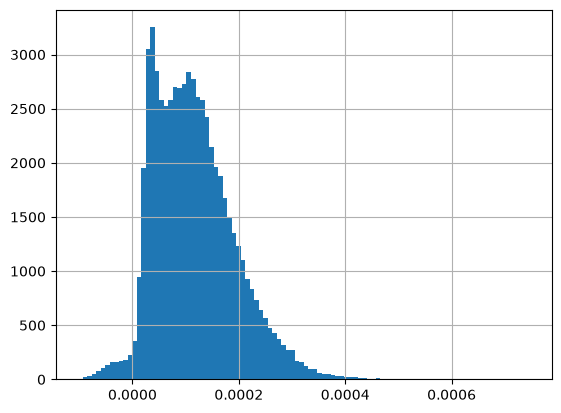

In [125]:
(
    baseline_scenario_anemia_yld_rates - intervention_anemia_yld_rates
).anemic_yld_rate.hist(bins=100)

In [126]:
zero_fort_scenario_ylds = (
    zero_fort_scenario_anemia_yld_rates.anemic_yld_rate.unstack("draw").mean(axis=1)
    * non_pregnant_pop
)
zero_fort_scenario_ylds

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  769.322283
                               2                  704.147434
                               3                  595.021286
                               4                  465.204098
                               5                  356.958318
                                                     ...    
Male    95.0       125.000000  1                  277.157686
                               2                  245.345964
                               3                  248.973465
                               4                  243.106705
                               5                  303.726981
Length: 250, dtype: float64

In [127]:
baseline_scenario_ylds = (
    baseline_scenario_anemia_yld_rates.anemic_yld_rate.unstack("draw").mean(axis=1)
    * non_pregnant_pop
)
baseline_scenario_ylds

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  763.667695
                               2                  697.185072
                               3                  587.455693
                               4                  458.027252
                               5                  350.680704
                                                     ...    
Male    95.0       125.000000  1                  277.174297
                               2                  245.104098
                               3                  248.264927
                               4                  242.156880
                               5                  302.191246
Length: 250, dtype: float64

In [128]:
intervention_scenarios_ylds = (
    intervention_anemia_yld_rates.anemic_yld_rate.unstack("draw").mean(axis=1)
    * non_pregnant_pop
)
intervention_scenarios_ylds

sex     age_start  age_end     wealth_quintile  scenario    
Female  0.0        0.019178    1                intervention    761.653570
                               2                intervention    694.705128
                               3                intervention    584.760882
                               4                intervention    455.470910
                               5                intervention    348.444662
                                                                   ...    
Male    95.0       125.000000  1                intervention    277.180213
                               2                intervention    245.017947
                               3                intervention    248.012551
                               4                intervention    241.818560
                               5                intervention    301.644228
Length: 250, dtype: float64

In [129]:
(
    baseline_scenario_ylds.loc[("Female", 25, 30, 1)].mean()
    - intervention_scenarios_ylds.loc[("Female", 25, 30, 1)].mean()
)

np.float64(111.90635292596198)

In [130]:
(
    baseline_scenario_ylds.groupby(["wealth_quintile"]).sum()
    - intervention_scenarios_ylds.groupby(["scenario", "wealth_quintile"]).sum()
)

scenario      wealth_quintile
intervention  1                  3977.482147
              2                  5194.044239
              3                  5870.267095
              4                  6034.112398
              5                  5938.448713
dtype: float64

In [131]:
ylds = pd.concat(
    [
        zero_fort_scenario_ylds.rename("value").reset_index().assign(scenario="zero"),
        baseline_scenario_ylds.rename("value")
        .reset_index()
        .assign(scenario="baseline"),
        intervention_scenarios_ylds.rename("value").reset_index(),
    ],
    ignore_index=True,
)
ylds

,sex,age_start,age_end,wealth_quintile,value,scenario
0,Female,0.0,0.019178,1,769.322283,zero
1,Female,0.0,0.019178,2,704.147434,zero
2,Female,0.0,0.019178,3,595.021286,zero
3,Female,0.0,0.019178,4,465.204098,zero
4,Female,0.0,0.019178,5,356.958318,zero
...,...,...,...,...,...,...
745,Male,95.0,125.000000,1,277.180213,intervention
746,Male,95.0,125.000000,2,245.017947,intervention
747,Male,95.0,125.000000,3,248.012551,intervention
748,Male,95.0,125.000000,4,241.818560,intervention


In [132]:
results_dir = (
    paths.output_root(paths.NON_PREGNANT_ANEMIA_RESULTS_ROOT)
    / vehicle.lower()
    / location.lower()
)

In [133]:
path = f"{results_dir}/ylds.parquet"
pathlib.Path(path).parent.mkdir(exist_ok=True, parents=True)
ylds.to_parquet(path)

In [134]:
zero_fort_anemia_prevalence = (
    zero_fort_scenario_anemia_by_severity["anemic"].unstack("draw").mean(axis=1)
)
zero_fort_anemia_prevalence

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  0.820467
                               2                  0.805018
                               3                  0.797293
                               4                  0.786481
                               5                  0.750670
                                                    ...   
Male    95.0       125.000000  1                  0.709580
                               2                  0.717624
                               3                  0.727471
                               4                  0.729869
                               5                  0.737662
Length: 250, dtype: float64

In [135]:
baseline_anemia_prevalence = (
    baseline_scenario_anemia_by_severity["anemic"].unstack("draw").mean(axis=1)
)
baseline_anemia_prevalence

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  0.817277
                               2                  0.800608
                               3                  0.791537
                               4                  0.779353
                               5                  0.742332
                                                    ...   
Male    95.0       125.000000  1                  0.707832
                               2                  0.715184
                               3                  0.724330
                               4                  0.726327
                               5                  0.733802
Length: 250, dtype: float64

In [136]:
zero_fort_anemia_cases = zero_fort_anemia_prevalence.mul(non_pregnant_pop, axis=0)
zero_fort_anemia_cases

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  15419.157400
                               2                  14353.961507
                               3                  12860.061574
                               4                  11100.415227
                               5                   9164.508151
                                                      ...     
Male    95.0       125.000000  1                   3441.215785
                               2                   3136.863175
                               3                   3324.483315
                               4                   3321.568039
                               5                   4242.040079
Length: 250, dtype: float64

In [137]:
zero_fort_anemia_cases.sum() / non_pregnant_pop.sum()

np.float64(0.48063601826106106)

In [138]:
baseline_anemia_cases = baseline_anemia_prevalence.mul(non_pregnant_pop, axis=0)
baseline_anemia_cases

sex     age_start  age_end     wealth_quintile
Female  0.0        0.019178    1                  15359.206429
                               2                  14275.334355
                               3                  12767.217709
                               4                  10999.814937
                               5                   9062.719624
                                                      ...     
Male    95.0       125.000000  1                   3432.737380
                               2                   3126.199387
                               3                   3310.129369
                               4                   3305.445461
                               5                   4219.841669
Length: 250, dtype: float64

In [139]:
baseline_anemia_cases.sum() / non_pregnant_pop.sum()

np.float64(0.4730793426194682)

In [140]:
baseline_anemia_cases.groupby(["wealth_quintile"]).sum() / non_pregnant_pop.groupby(
    ["wealth_quintile"]
).sum()

wealth_quintile
1    0.523390
2    0.509665
3    0.470846
4    0.443487
5    0.418852
dtype: float64

In [141]:
intervention_anemia_prevalence = (
    intervention_scenarios_anemia_by_severity["anemic"].unstack("draw").mean(axis=1)
)
intervention_anemia_prevalence

sex     age_start  age_end     wealth_quintile  scenario    
Female  0.0        0.019178    1                intervention    0.816141
                               2                intervention    0.799037
                               3                intervention    0.789486
                               4                intervention    0.776815
                               5                intervention    0.739362
                                                                  ...   
Male    95.0       125.000000  1                intervention    0.707209
                               2                intervention    0.714315
                               3                intervention    0.723211
                               4                intervention    0.725065
                               5                intervention    0.732427
Length: 250, dtype: float64

In [142]:
anemia_prevalence = pd.concat(
    [
        zero_fort_anemia_prevalence.rename("value")
        .reset_index()
        .assign(scenario="zero"),
        baseline_anemia_prevalence.rename("value")
        .reset_index()
        .assign(scenario="baseline"),
        intervention_anemia_prevalence.rename("value").reset_index(),
    ],
    ignore_index=True,
)
anemia_prevalence

,sex,age_start,age_end,wealth_quintile,value,scenario
0,Female,0.0,0.019178,1,0.820467,zero
1,Female,0.0,0.019178,2,0.805018,zero
2,Female,0.0,0.019178,3,0.797293,zero
3,Female,0.0,0.019178,4,0.786481,zero
4,Female,0.0,0.019178,5,0.750670,zero
...,...,...,...,...,...,...
745,Male,95.0,125.000000,1,0.707209,intervention
746,Male,95.0,125.000000,2,0.714315,intervention
747,Male,95.0,125.000000,3,0.723211,intervention
748,Male,95.0,125.000000,4,0.725065,intervention


In [143]:
path = f"{results_dir}/anemia_prevalence.parquet"
pathlib.Path(path).parent.mkdir(exist_ok=True, parents=True)
anemia_prevalence.to_parquet(path)

In [144]:
intervention_anemia_cases = intervention_anemia_prevalence.mul(non_pregnant_pop, axis=0)
intervention_anemia_cases

sex     age_start  age_end     wealth_quintile  scenario    
Female  0.0        0.019178    1                intervention    15337.852317
                               2                intervention    14247.327921
                               3                intervention    12734.147382
                               4                intervention    10963.981826
                               5                intervention     9026.463272
                                                                    ...     
Male    95.0       125.000000  1                intervention     3429.717432
                               2                intervention     3122.401021
                               3                intervention     3305.016595
                               4                intervention     3299.702713
                               5                intervention     4211.934752
Length: 250, dtype: float64

In [145]:
intervention_anemia_cases.sum() / non_pregnant_pop.sum()

np.float64(0.4703877082738087)

In [146]:
intervention_anemia_cases.groupby(["wealth_quintile"]).sum() / non_pregnant_pop.groupby(
    ["wealth_quintile"]
).sum()

wealth_quintile
1    0.521764
2    0.507426
3    0.467942
4    0.440274
5    0.415391
dtype: float64

In [147]:
(
    baseline_anemia_cases.groupby(["wealth_quintile"]).sum()
    - intervention_anemia_cases.groupby(["wealth_quintile"]).sum()
).map(lambda x: f"{round(x):,.0f}")

wealth_quintile
1     75,517
2    104,946
3    136,687
4    151,672
5    162,690
dtype: str

In [148]:
anemia_cases = pd.concat(
    [
        zero_fort_anemia_cases.rename("value").reset_index().assign(scenario="zero"),
        baseline_anemia_cases.rename("value").reset_index().assign(scenario="baseline"),
        intervention_anemia_cases.rename("value").reset_index(),
    ],
    ignore_index=True,
)
anemia_cases

,sex,age_start,age_end,wealth_quintile,value,scenario
0,Female,0.0,0.019178,1,15419.157400,zero
1,Female,0.0,0.019178,2,14353.961507,zero
2,Female,0.0,0.019178,3,12860.061574,zero
3,Female,0.0,0.019178,4,11100.415227,zero
4,Female,0.0,0.019178,5,9164.508151,zero
...,...,...,...,...,...,...
745,Male,95.0,125.000000,1,3429.717432,intervention
746,Male,95.0,125.000000,2,3122.401021,intervention
747,Male,95.0,125.000000,3,3305.016595,intervention
748,Male,95.0,125.000000,4,3299.702713,intervention


In [149]:
path = f"{results_dir}/anemia_cases.parquet"
pathlib.Path(path).parent.mkdir(exist_ok=True, parents=True)
anemia_cases.to_parquet(path)